In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from tqdm import tqdm
from scipy.optimize import curve_fit
from scipy import stats
import math
import chemparse
import pickle
import os
import zipfile
from statistics import mean, stdev
import warnings
from networkx.algorithms import bipartite
from netgraph import get_multipartite_layout
import csv
from collections import Counter

from NetworkExpansion import *
from utilities import *

# To avoid future warnings in network expansion
tqdm.pandas()
pd.set_option('future.no_silent_downcasting', True)  
warnings.filterwarnings("ignore")

# Matplotlib defaults
font = {"sans-serif": "DejaVu Sans", "size": 22}
for key, value in font.items():
        plt.rcParams.update({"font." + key: value})

# SI Figure details
fig_count = 1
fig_path = "../Figures/SIFigures/SIFig_"


/Users/johnmalloy/Lab/Chirality/ChiralExpansion/Code/NetworkExpansion.py:165: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  ec_rns = pd.read_csv('https://rest.kegg.jp/link/enzyme/reaction', sep='\t', header=None).applymap(


# JGI 

Includes scatter plots and achiral/crossover plots for each domain, plus metagenomes

## Scatter Plots of chirality of individual samples

In [2]:
def linlaw(x, a, b) :
    return a * x + b

def powerlaw(x, a, b, c):
    return b*x**a + c

def curve_fit_log_linear(xdata, ydata) :
    xdata_log = np.log10(xdata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata)
    # y variables as results from fitting
    ydatafit = linlaw(xdata_log, *popt_log)
    return (popt_log, pcov_log, ydatafit)

def curve_fit_log_log(xdata, ydata) :
    
    xdata_log = np.log10(xdata)
    ydata_log = np.log10(ydata)
    # Fit linear
    popt_log, pcov_log = curve_fit(linlaw, xdata_log, ydata_log)
    # y variables as results from fitting
    ydatafit = pow(10, linlaw(xdata_log, *popt_log))
    return (popt_log, pcov_log, ydatafit)

def find_fit(X,Y,color,ax):
    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=0, stop=max(X), num=100)
    ax.plot(x_dummy,slope*x_dummy + intercept,color=color)
    ax.fill_between(x_dummy,slope*x_dummy+intercept-std_err,slope*x_dummy+intercept+std_err,color=color, alpha=0.2)


def find_powerlaw_fit(x,y,color):
    if x == 0:
        x = 0.000001
    if y == 0:
        y = 0.000001
    X = np.log10(x)
    Y = np.log10(y)

    slope, intercept, r_value, p_value, std_err = stats.linregress(X,Y)
    print('Slope: {:.6f}'.format(slope),'Intercept: {:.6f}'.format(intercept),'R-squared: {:.6f}'.format(r_value**2),'Std_err: {:.6f}'.format(std_err))
    x_dummy = np.linspace(start=-500, stop=8000, num=100)
    plt.plot(x_dummy,(10**intercept)*(x_dummy**slope) ,color=color)


In [3]:
data_dir = "../Data/"
df = dict()
for domain in ["Archaea", "Metagenome", "Bacteria", "Eukarya", "Biosphere", "LUCA"]:
    df[domain] = pd.read_csv(data_dir + "species_chirality_in_%s.csv"%domain)

color_number = {"LUCA":"#10D410", "Archaea":"#D65E00", "Bacteria":"#0B77B5", 
                "Eukarya":"#E69F03", "Metagenome":"#009E73", "Biosphere": "#4B0092"} 

Slope: -0.000106 Intercept: 0.739776 R-squared: 0.346741 Std_err: 0.000004
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000074 Intercept: 0.708940 R-squared: 0.494065 Std_err: 0.000001
Slope: -0.000027 Intercept: 0.653523 R-squared: 0.200469 Std_err: 0.000003
Slope: 0.000009 Intercept: 0.572096 R-squared: 0.097244 Std_err: 0.000000


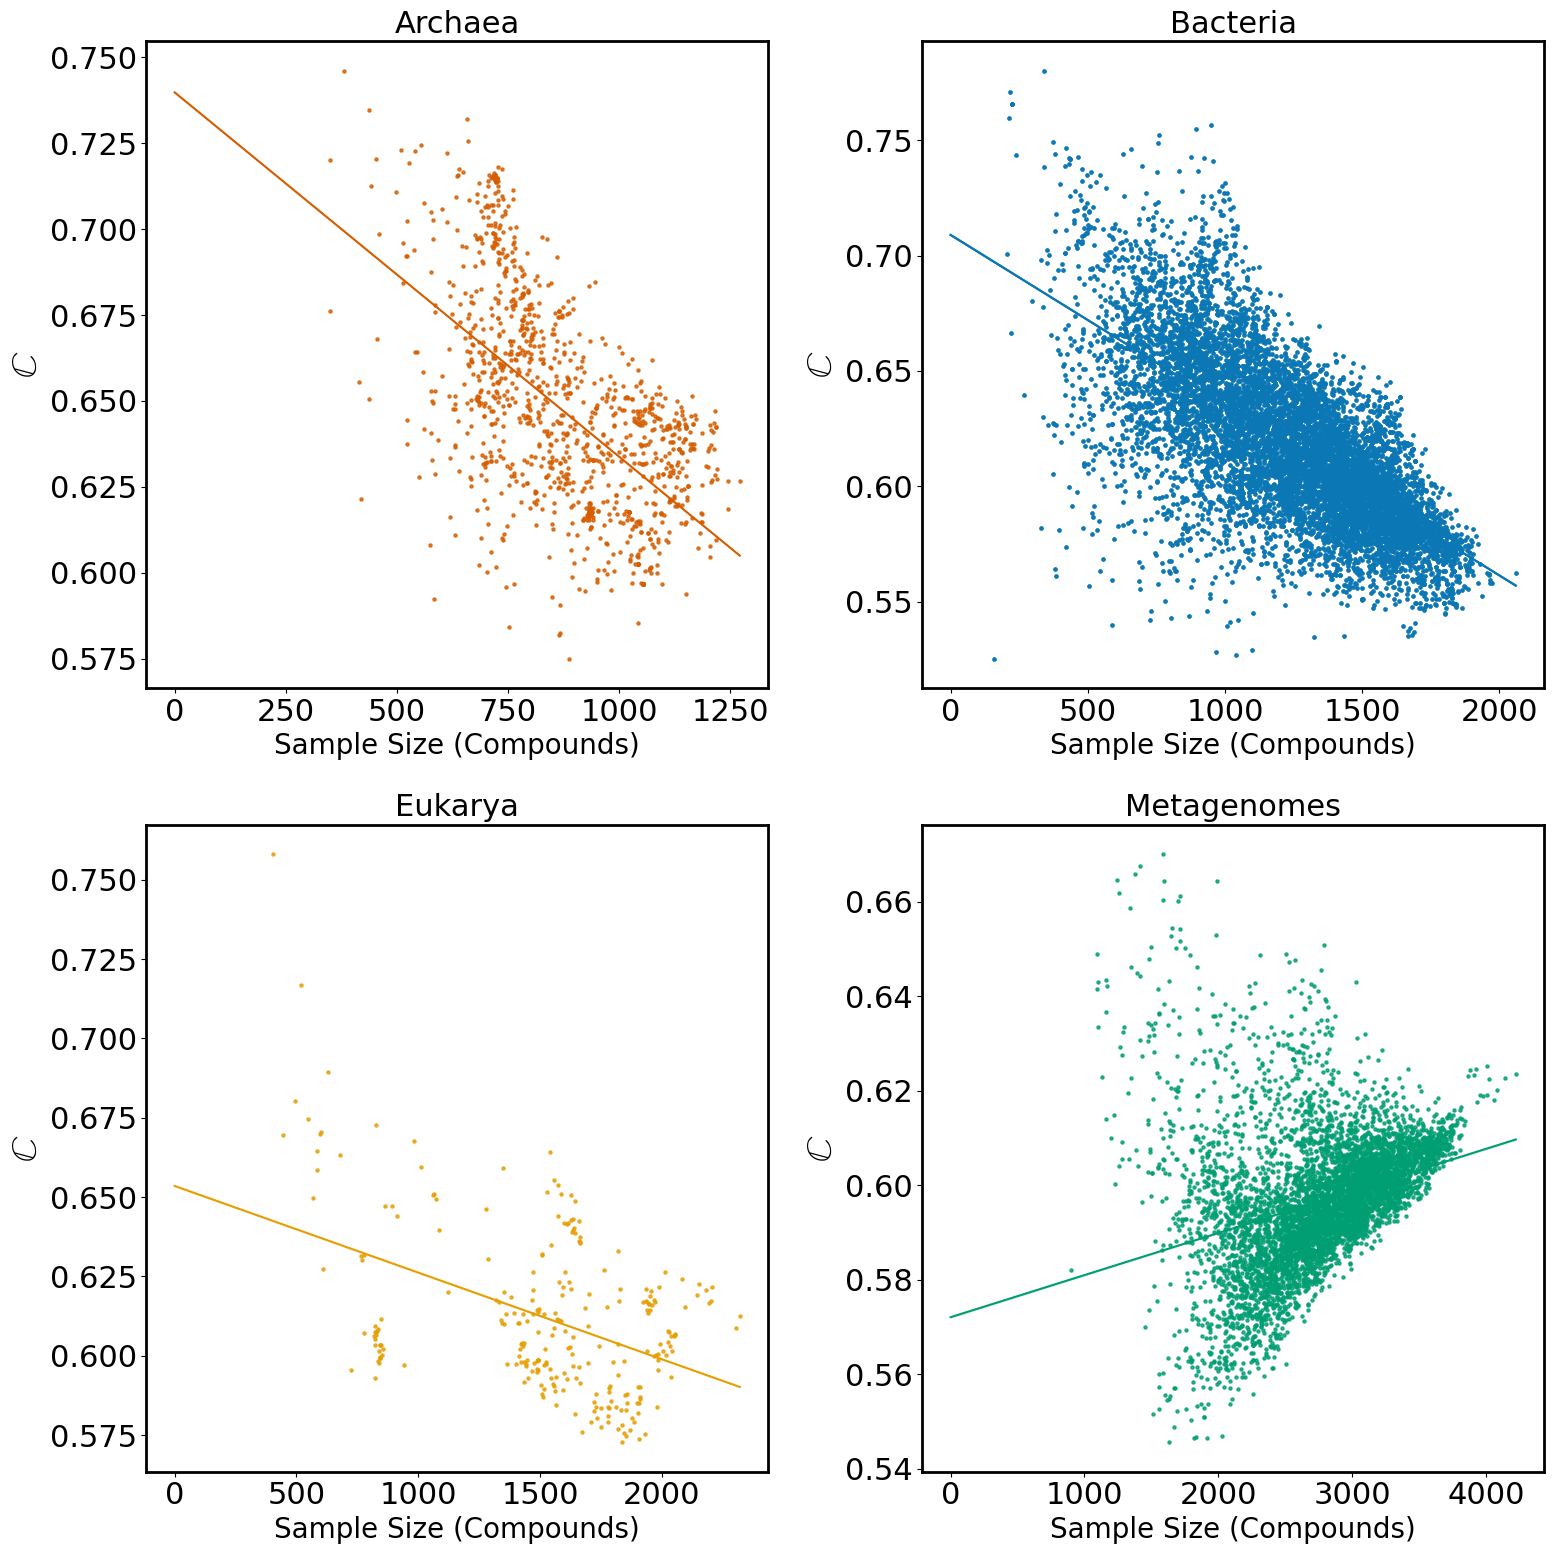

In [ ]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(2,2)

# Archaea
ax1 = plt.subplot(gs[0,0])
handles = []
domain = "Archaea"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax1.set_title(domain, fontsize=22)

ax1 = plt.subplot(gs[0,1])
handles = []
domain = "Bacteria"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax1.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax1)
ax1.set_ylabel("$\mathbb{C}$", fontsize=26)
ax1.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax1.set_title(domain, fontsize=22)

#Eukarya
ax3 = plt.subplot(gs[1,0])
handles = []
domain = "Eukarya"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax3.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax3)
ax3.set_ylabel("$\mathbb{C}$", fontsize=26)
ax3.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax3.set_title(domain, fontsize=22)

#Metagenomes
ax4 = plt.subplot(gs[1,1])
handles = []
domain = "Metagenome"
x = df[domain].total_size
y = df[domain].ratio_chiral
s = ax4.scatter(x, y, label = domain, s=5, color=color_number[domain], alpha=0.8)
handles.append(s) #Adding lines to an array for legend labeling
find_fit(x, y, color_number[domain], ax4)
ax4.set_ylabel("$\mathbb{C}$", fontsize=26)
ax4.set_xlabel("Sample Size (Compounds)", fontsize=20)
ax4.set_title(domain + "s", fontsize=22)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

## Chiral/Achiral crossover (by domain)

In [5]:
### Find which formulas appear in domains
def find_domain(formula, domain_cpds):
    if formula in domain_cpds:
        return 1
    else:
        return 0
    
def getNumHeavyAtoms(f):
    """ Find the number of heavy atoms (non-Hs)

    Args:
        f (dict): dictionary of elements & atom counts

    Returns:
        int: number of non-H atoms
    """
    #Remove Hs
    if "H" in f:
        f.pop("H")

    #Count number of other atoms (heavy atoms are non-Hs)
    return sum(f.values())

def getFormulaDict(f):
    
    return chemparse.parse_formula(f)

In [6]:
keggC_df = pd.read_csv("../../lets-get-kegg/Data/kegg_data_C.csv.zip",
                       index_col=0,
                       compression="zip")

for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
    print("---- Analyzing", domain, "----")
    domain_df = pd.read_csv("../Data/" + domain + "_occurance.csv")
    domain_cpds = list(domain_df["Cpd"])

    keggC_df[domain] = keggC_df["compound_id"].apply(find_domain, args=(domain_cpds,))


---- Analyzing archaea ----
---- Analyzing bacteria ----
---- Analyzing metagenome ----
---- Analyzing eukarya ----


In [7]:
### Get all column sorted out - if a compound is present in bacteria, eukarya, archaea, or metagenome, "all" should be 1
all_column = []

for _, row in keggC_df.iterrows():
    found_cpd = 0
    for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
        if row[domain] == 1 and found_cpd == 0:
            all_column.append(1)
            found_cpd = 1
    if found_cpd == 0:
        all_column.append(0)

keggC_df["all"] = all_column

In [8]:
### Goal - chiral/achiral fraction at each heavy atom value
def get_chiral_fraction(df, domain):
    chiral_fraction = []
    # chiral_fraction = []

    for i in range(1, int(max(df["n_heavy_atoms"]))):
        sub_df = df[df["n_heavy_atoms"] == i]
        #Filter by domain, if domain exists
        if domain:
            sub_df = sub_df[sub_df[domain] == 1]
        else:
            pass

        if len(sub_df) >= 1:
            chiral_fraction.append(float(sub_df["n_chiral_centers"].astype(bool).sum(axis=0) / len(sub_df)))
            # if len(sub_df) < 5 or i == 10:
            #     print(i, sub_df["Chiral_Centers"].astype(bool).sum(axis=0), float(len(sub_df)))
        else:
            chiral_fraction.append(float("NaN"))

    achiral_fraction = []

    for cf in chiral_fraction:
        if not math.isnan(cf):
            achiral_fraction.append(1 - cf)
        else:
            achiral_fraction.append(float("NaN"))

    return chiral_fraction, achiral_fraction

In [9]:
achiral_color = "#FFC012"
chiral_color = "#34CCFF"

In [10]:
print("---- Metagenomes ---")
mg_chiral_fraction, mg_achiral_fraction = get_chiral_fraction(keggC_df, "metagenome")

print("---- Bacteria ---")
b_chiral_fraction, b_achiral_fraction = get_chiral_fraction(keggC_df, "bacteria")

print("---- Archaea ---")
a_chiral_fraction, a_achiral_fraction = get_chiral_fraction(keggC_df, "archaea")

print("---- Eukarya ---")
e_chiral_fraction, e_achiral_fraction = get_chiral_fraction(keggC_df, "eukarya")

print("---- Metagenomes, Bacteria, Archaea, and Eukarya ----")
all_chiral_fraction, all_achiral_fraction = get_chiral_fraction(keggC_df, "all")


---- Metagenomes ---
---- Bacteria ---
---- Archaea ---
---- Eukarya ---
---- Metagenomes, Bacteria, Archaea, and Eukarya ----


<Figure size 800x800 with 0 Axes>

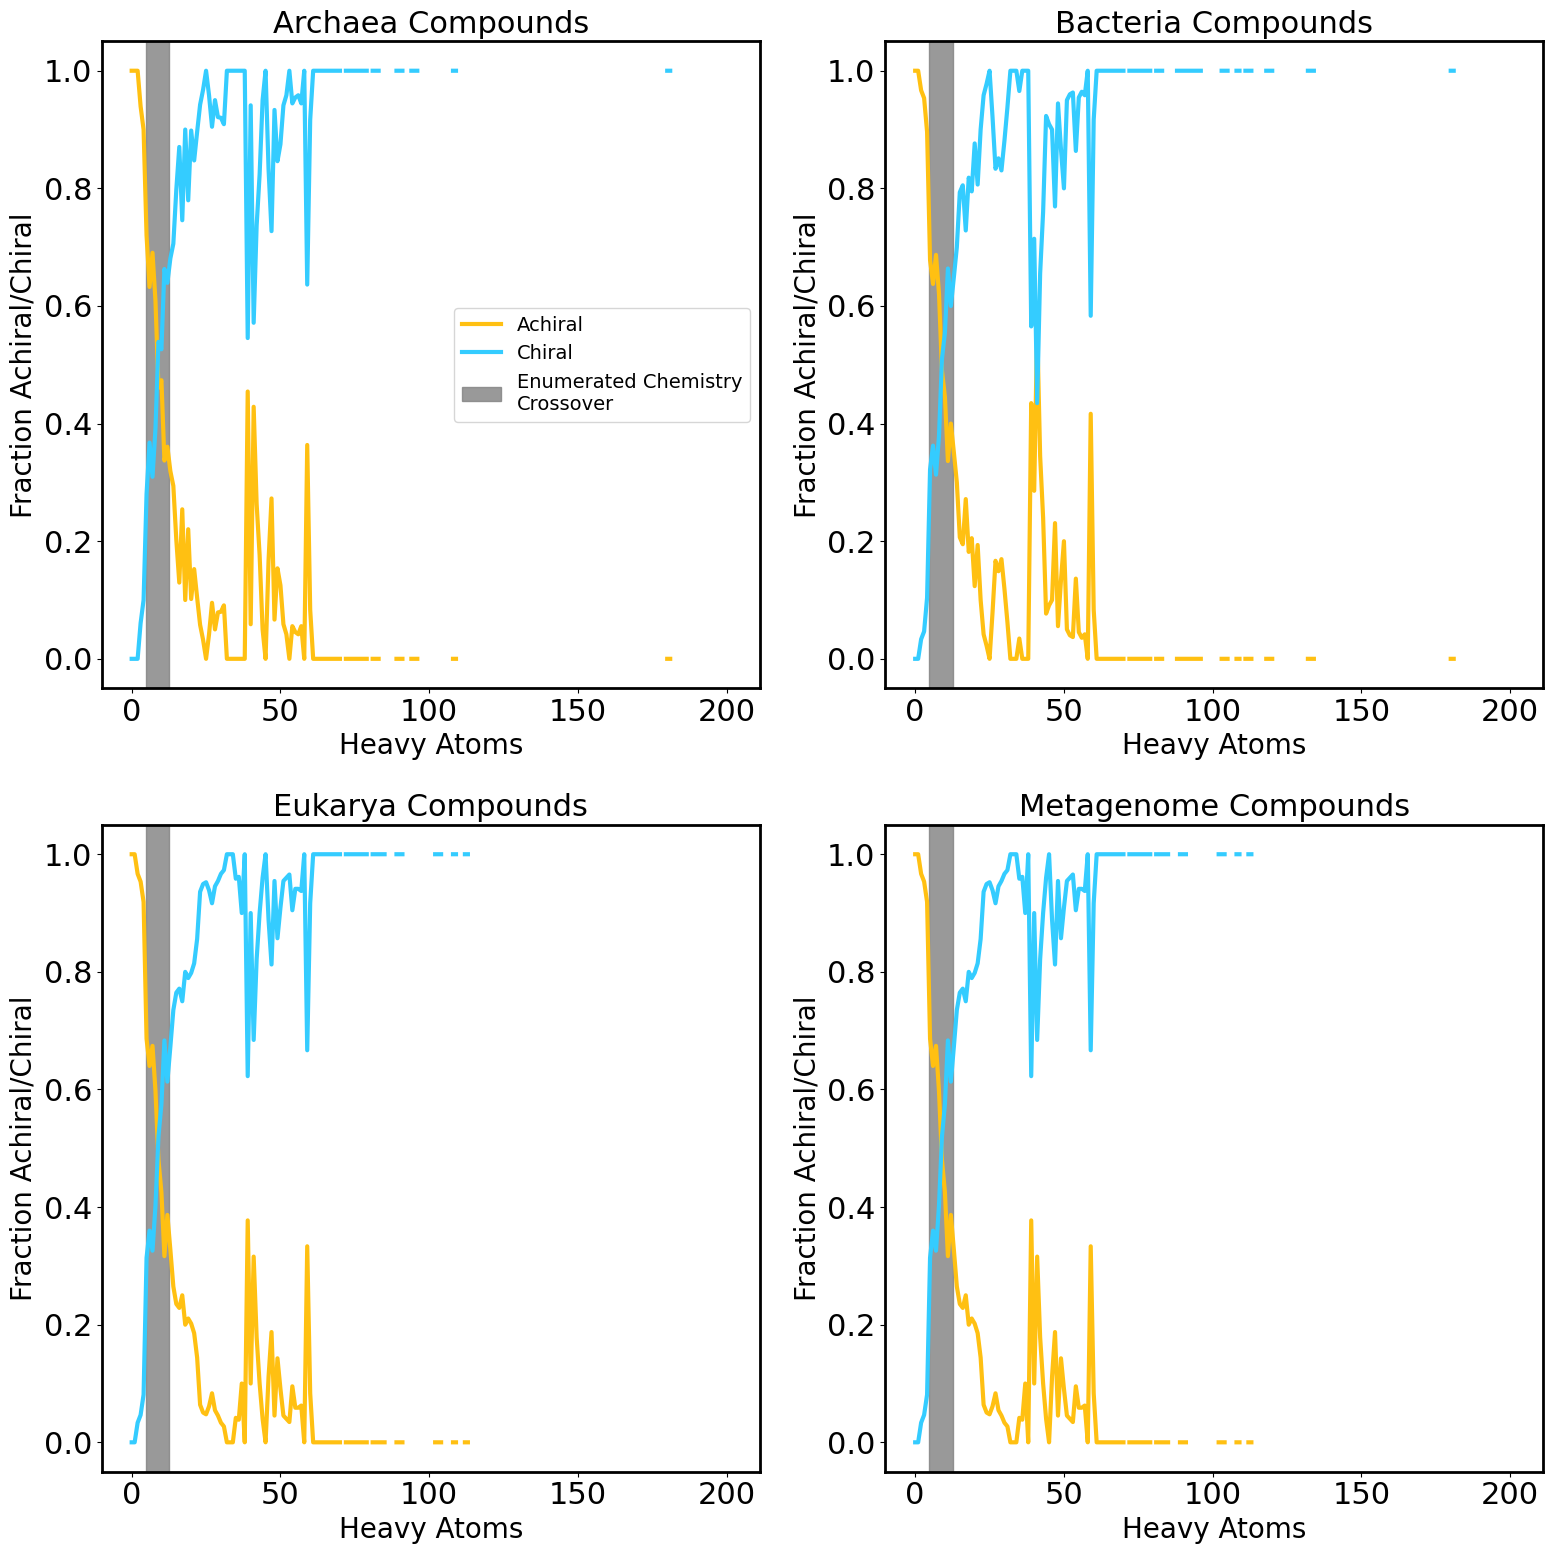

In [11]:
plt.figure(figsize=(8,8))

plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(2,2)

# Archaea
ax1 = plt.subplot(gs[0,0])
ax1.plot(a_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(a_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax1.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax1.set_title("Archaea Compounds", fontsize=22)
ax1.legend(prop={"size":14}, facecolor="white")
ax1.set_xlabel("Heavy Atoms", fontsize=20)
ax1.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Bacteria
ax2 = plt.subplot(gs[0,1])
ax2.plot(b_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(b_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax2.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax2.set_title("Bacteria Compounds", fontsize=22)
ax2.set_xlabel("Heavy Atoms", fontsize=20)
ax2.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Eukarya
ax3 = plt.subplot(gs[1,0])
ax3.plot(e_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax3.plot(e_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax3.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax3.set_title("Eukarya Compounds", fontsize=22)
ax3.set_xlabel("Heavy Atoms", fontsize=20)
ax3.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

#Metagenomes
ax4 = plt.subplot(gs[1,1])
ax4.plot(e_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax4.plot(e_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax4.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")
ax4.set_title("Metagenome Compounds", fontsize=22)
ax4.set_xlabel("Heavy Atoms", fontsize=20)
ax4.set_ylabel("Fraction Achiral/Chiral", fontsize=20)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

#### Fraction chiral/achiral with standard deviations

No domain data attached

In [12]:
### NOTE: TAKES ~7 MINUTES

#Achiral/chiral stats over all JGI samples
chiral_fracs = []
achiral_fracs = []

with zipfile.ZipFile("../Data/JGI_metagenomes.zip") as z:
      for filename in tqdm(z.namelist()):
            if filename.endswith(".csv"):
                  s1_df = pd.read_csv(z.open(filename))
                  s_df = keggC_df[keggC_df["compound_id"].isin(list(s1_df.compounds))]
                  chiral_fraction, achiral_fraction = get_chiral_fraction(s_df, None)
                  chiral_fracs.append(chiral_fraction)
                  achiral_fracs.append(achiral_fraction)

100%|██████████| 6113/6113 [04:41<00:00, 21.69it/s]


In [13]:
chiral_mean = list(map(np.mean, zip(*chiral_fracs)))
print(chiral_mean)

achiral_mean = list(map(np.mean, zip(*achiral_fracs)))
print(achiral_mean)

chiral_std = list(map(np.std, zip(*chiral_fracs)))
print(chiral_std)

achiral_std = list(map(np.std, zip(*achiral_fracs)))
print(achiral_std)

[np.float64(0.0), np.float64(0.0), np.float64(0.03194814512100824), np.float64(0.052664997462647904), np.float64(0.09241257405853118), np.float64(0.3222978538494611), np.float64(0.3578939880725695), np.float64(0.2987035570512067), np.float64(0.38365662221783103), np.float64(0.5162637129789246), np.float64(0.5451705715190533), np.float64(0.6664850844148845), np.float64(0.6284597286074198), np.float64(0.6930581482411634), np.float64(0.7324717877950443), np.float64(0.8159601135597883), np.float64(0.8263471818147278), np.float64(0.7595254986096096), np.float64(0.8862355556305935), np.float64(0.8096949165607826), np.float64(0.8784470152109451), np.float64(0.8370041633973633), np.float64(0.8941960338013972), np.float64(0.9646049712235679), np.float64(0.9843681828673666), np.float64(0.9969294431678535), np.float64(0.9597415927206165), np.float64(0.9042683501127625), np.float64(0.9028285028499433), np.float64(0.9273558788755976), np.float64(0.9485644579978082), np.float64(0.963567963136809), n

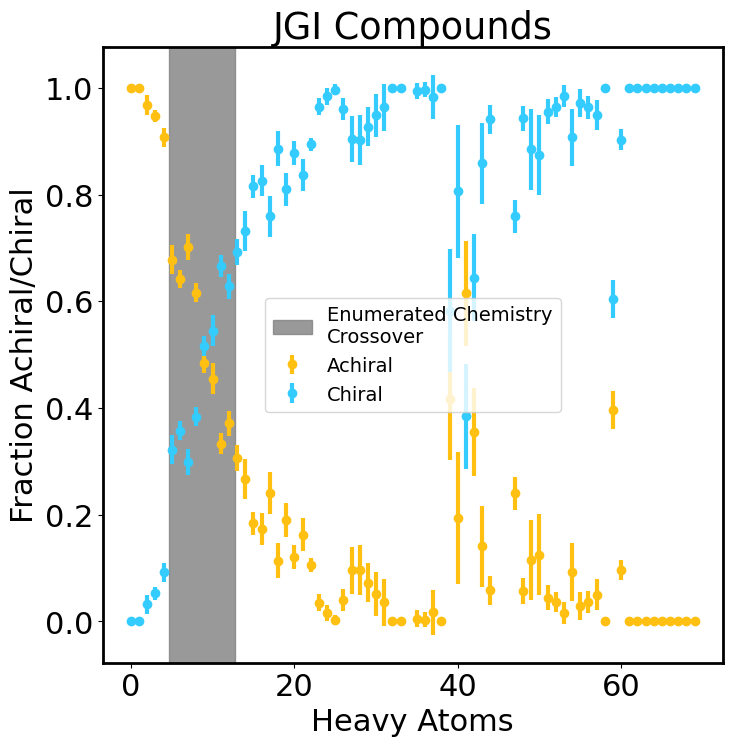

In [14]:
### JGI fuzzy graph
plt.figure(figsize=(8,8))

plt.errorbar(x=list(range(len(achiral_mean))), y=achiral_mean, yerr=achiral_std, fmt="o", linewidth=3, label="Achiral", color=achiral_color)
plt.errorbar(x=list(range(len(chiral_mean))), y=chiral_mean, yerr=chiral_std, fmt="o", linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Enumerated Chemistry\nCrossover")

plt.title("JGI Compounds")
plt.legend(prop={"size":14})

plt.xlabel("Heavy Atoms")
plt.ylabel("Fraction Achiral/Chiral")

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

In [15]:
del(chiral_fracs)
del(achiral_fracs)

#### GDB / JGI / Chiral Order Parameter, no x-limits

In [16]:
gdb_df = pd.read_csv("../Data/GDB_output.csv")

## GDB chiral order parameter (cop = "Chiral Order Parameter")
gdb_counts_df = pd.read_csv("../Data/GDB_raw_counts.csv")
gdb_cop = []

for _, row in gdb_counts_df.iterrows():
    gdb_cop.append(row["count_chiral"] / (row["count_achiral"] + row["count_chiral"]))

## JGI cop
JGI_cop = []
sub_df = keggC_df[keggC_df["all"] == 1]
for i in range(70):
    sub_df2 = sub_df[sub_df["n_heavy_atoms"] == i]
    achiral = len(sub_df2[sub_df2["n_chiral_centers"] == 0])
    chiral = len(sub_df2[sub_df2["n_chiral_centers"] != 0])
    if achiral + chiral != 0:
        JGI_cop.append(chiral / (achiral + chiral))
    else:
        JGI_cop.append(None)

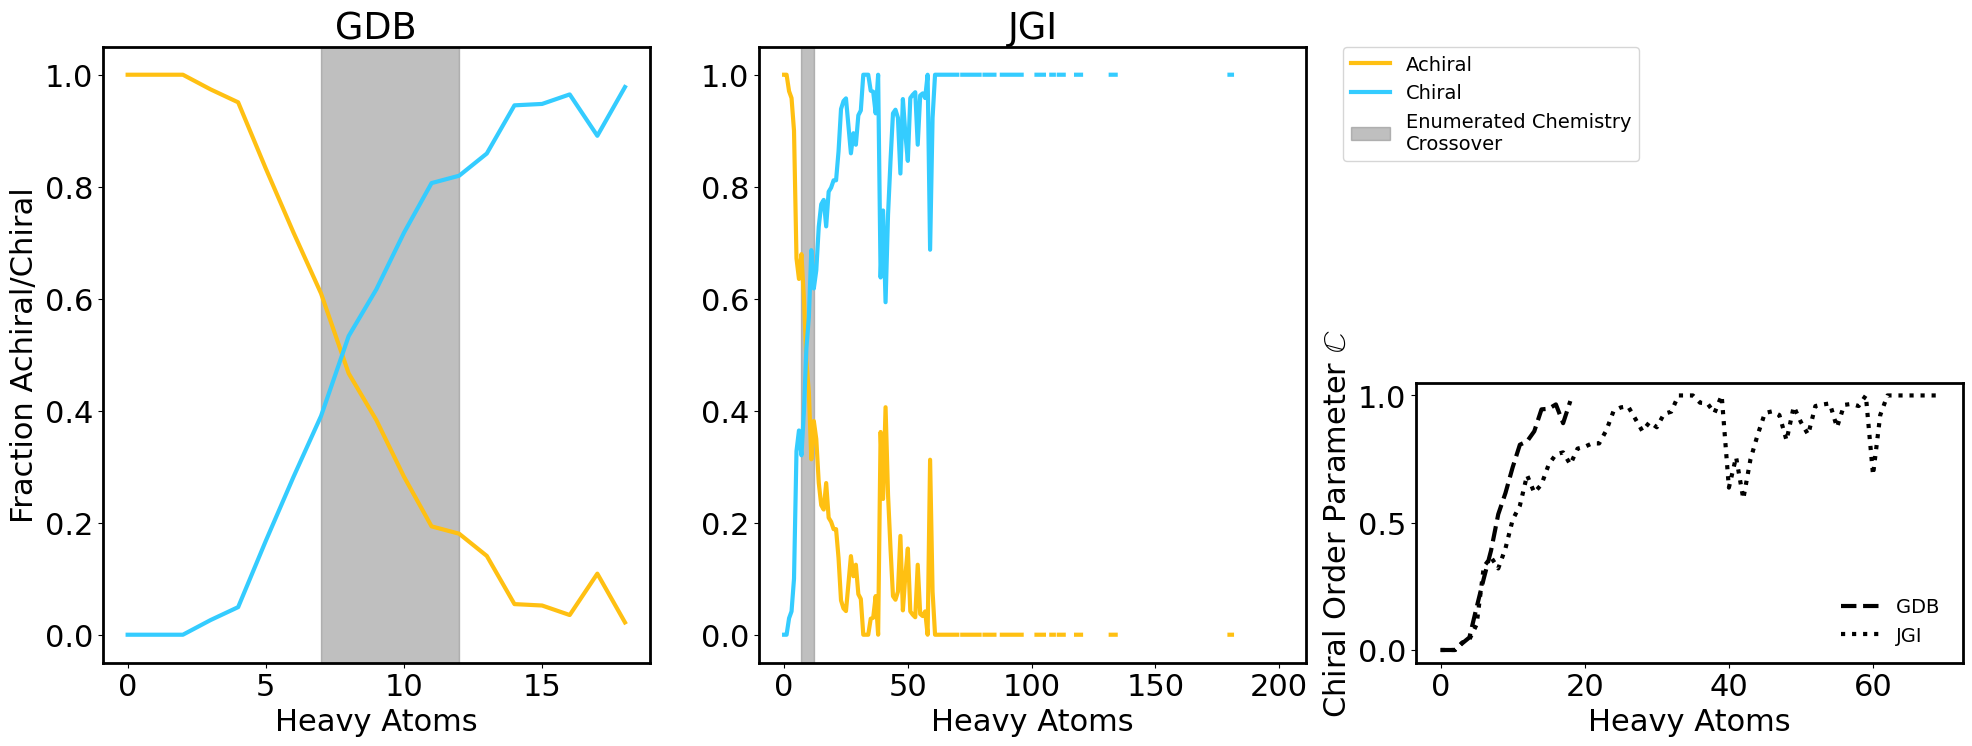

In [ ]:
plt.rcParams['figure.constrained_layout.use'] = False

plt.figure(figsize=(24,8))

gs = gridspec.GridSpec(2,6)

ax1 = plt.subplot(gs[:,0:2])
ax1.plot(gdb_df["fraction_achiral"], linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(gdb_df["fraction_chiral"], linewidth=3, label="Chiral", color=chiral_color)
ax1.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

#ax1.set_xlim(0,16)
ax1.set_ylim(-0.05, 1.05)
ax1.set_xlabel("Heavy Atoms")
ax1.set_ylabel("Fraction Achiral/Chiral")
ax1.set_title("GDB")


ax2 = plt.subplot(gs[:,2:4])
ax2.plot(all_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(all_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)
ax2.axvspan(7, 12, alpha=0.5, color='grey', label="Enumerated Chemistry\nCrossover")

ax2.legend(prop={"size":14}, bbox_to_anchor=(1.05, 1.015))

#ax2.set_xlim(0,16)
ax2.set_ylim(-0.05, 1.05)
ax2.set_xlabel("Heavy Atoms")
ax2.set_title("JGI")

ax3 = plt.subplot(gs[1,4:])
ax3.plot(gdb_cop, linewidth=3, label="GDB ", color="k", linestyle="--")
ax3.plot(JGI_cop, linewidth=3, label="KEGG", color="k", linestyle=":")

ax3.legend(frameon=False, prop={"size":14})
#ax3.set_xlim(0,16)
ax3.set_ylim(-0.05, 1.05)
ax3.set_xlabel("Heavy Atoms")
ax3.set_ylabel("Chiral Order Parameter $\mathbb{C}$")
ax3.annotate(xy=(150,0.4), text=r"$\mathbb{C} = \frac{C}{C+A}$", )

plt.subplots_adjust(wspace=0.5)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

# Network Expansion

## Primordial Expansions

In [18]:
#make compound: num chiral centers dictionary
cpd_ccs = dict(zip(keggC_df.compound_id, keggC_df.n_chiral_centers))

In [19]:
from NetworkExpansion import *

#Run network expansion processing
# Seed set
seed_name = "JM|G24|G17|TW"
rxn_db = "../../lets-get-kegg/Data/atlas_kegg_processed_merged_deduped.csv.zip"
max_generation = 1000 #Arbitrarily large 

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))

compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seed_sets = {
    i: seed_scope.query('Source.str.contains("' + i + '")').index
    for i in seed_groups
}
print(f"- Seed Set ({seed_name}) -")

### Run network expansion on original seed set
results = dict()
for name, seeds in seed_sets.items():
    print(seeds)
    results[name] = expand_from_seed_set(seeds=seeds,
                                            reactions=reaction_scope,
                                            max_gen=max_generation)
    results[name]['bipartite_edgelist'] = make_bipartite_edgelist(
        results[name]['edge_pool'])

### Process expansion (including chiral %s at each step & heavy atom count)
def result_to_df(key: str, to_apply):
    return pd.concat(
        {i: results[i][key].apply(to_apply) for i in results.keys()}, axis=1)

summaries = {
    'compound count':
        result_to_df(key='cps', to_apply=lambda x: x.sum()),
    'reaction count':
        result_to_df(key='rns', to_apply=lambda x: x.sum()),
    'chiral compound count':
        getCpdCount(results[seed_name]["cps"], keggC_df,
                    ischiral_flag=True),
    'achiral compound count':
        getCpdCount(results[seed_name]["cps"],
                    keggC_df,
                    ischiral_flag=False),
    'chiral fraction':
        result_to_df(key='chiral_fraction', to_apply=lambda x: x),
    'chiral avg heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=True,
                                        calc="mean"),
    'achiral avg heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=False,
                                        calc="mean"),
    'chiral std heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=True,
                                        calc="std"),
    'achiral std heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=False,
                                        calc="std")
}

### Determines achiral/chiral crossover & first chiral compound
achiral_chiral_crossover_step = 0
first_chiral_step = 0
cum_chiral_count = summaries["chiral compound count"][0].to_list()
cum_achiral_count = summaries["achiral compound count"][0].to_list()
for i in range(len(summaries["chiral compound count"][0].to_list())):
    if cum_chiral_count[i] > 0 and first_chiral_step == 0:
        first_chiral_step = i
    if cum_chiral_count[i] > cum_achiral_count[
        i] and achiral_chiral_crossover_step == 0:
        achiral_chiral_crossover_step = i

print("- Chirality Statistics -")
print(f"\tAchiral To Chiral Crossover Step: {achiral_chiral_crossover_step}")
print(f"\tFirst Chiral Compound Appearence Step: {first_chiral_step}")
print(f"\tExpansion Size At First Chiral Compound Appearence: {summaries['compound count'].iloc[first_chiral_step][seed_name]} Compounds, {summaries['reaction count'].iloc[first_chiral_step][seed_name]} Reactions")
print(f"\tAverage Achiral Heavy Atoms At Crossover Step: {round(summaries['achiral avg heavy atoms'].iloc[achiral_chiral_crossover_step][0], 3)}")

- Seed Set (JM|G24|G17|TW) -
Index(['C00697', 'C00033', 'C00058', 'C00283', 'C00288', 'C00001', 'C00009',
       'C00011', 'C00014', 'C00080', 'C00059', 'C00022', 'C00023', 'C00026',
       'C00028', 'C00030', 'C00036', 'C00042', 'C00048', 'C00069', 'C00070',
       'C00071', 'C00122', 'C00160', 'C00161', 'C00175', 'C00205', 'C00209',
       'C00238', 'C00282', 'C00305', 'C00383', 'C00417', 'C01330', 'C01335',
       'C01528', 'C01732', 'C06232', 'C14818', 'C14819', 'C17023', 'C19609',
       'C19806', 'C00027', 'C00076', 'C00488', 'C00698', 'C01324', 'C01326',
       'C01327', 'C01328', 'C05359', 'C06547', 'C19610', 'C19611', 'C20396',
       'C00067', 'C00111', 'C00708', 'C01353', 'C05684'],
      dtype='object', name='Compound_id')
- Chirality Statistics -
	Achiral To Chiral Crossover Step: 4
	First Chiral Compound Appearence Step: 1
	Expansion Size At First Chiral Compound Appearence: 247 Compounds, 2255 Reactions
	Average Achiral Heavy Atoms At Crossover Step: 7.467


In [20]:
new_chiral_count = []
new_achiral_count = []
for i in range(len(cum_chiral_count)):
    if i > 0:
        new_chiral_count.append(cum_chiral_count[i] - cum_chiral_count[i-1])
        new_achiral_count.append(cum_achiral_count[i] - cum_achiral_count[i-1])
    else:
        new_chiral_count.append(0)
        new_achiral_count.append(0)

new_total_count = [x+y for x,y in zip(new_chiral_count, new_achiral_count)]

In [21]:
chiral_color = "#34CCFF"
achiral_color = "#FFC012"
sum_color = "limegreen"

Final chiral count: 5928
Final achiral count: 2725


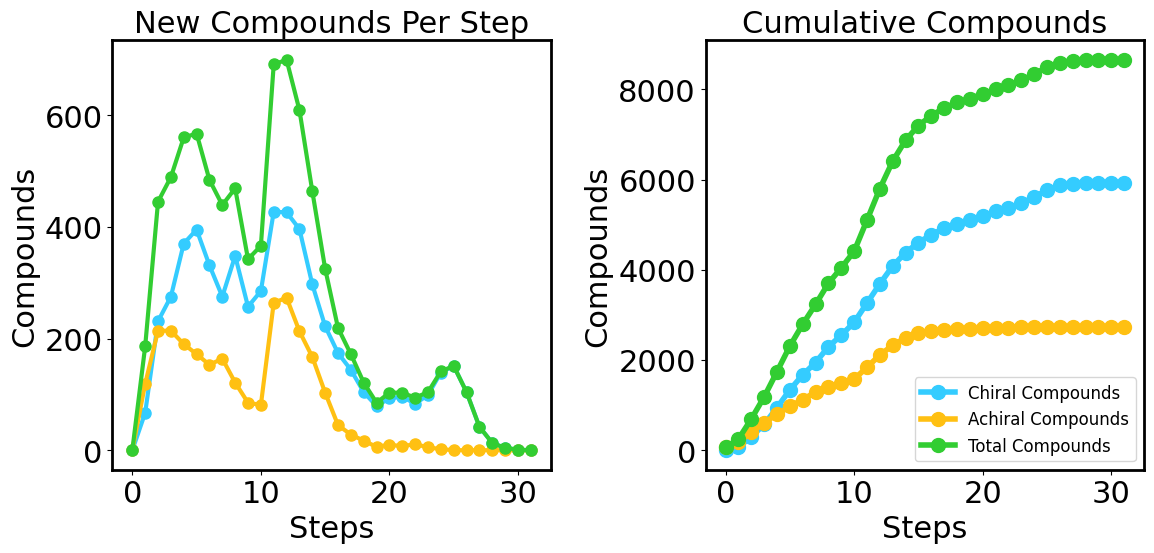

In [22]:
### Primordial Expansion plots
plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0,0])

ax1.plot(new_chiral_count, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Compounds",)
ax1.plot(new_achiral_count,  color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Compounds")
ax1.plot(np.arange(0, len(new_chiral_count), 1), new_total_count,
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Compounds")

#ax1.legend(facecolor="white", prop={"size": 12})
ax1.set_xlabel("Steps", fontsize=22)
ax1.set_ylabel("Compounds", fontsize=22)
ax1.set_title("New Compounds Per Step", fontsize=22)

#Cumulative plot
print(f"Final chiral count: {cum_chiral_count[-1]}")
print(f"Final achiral count: {cum_achiral_count[-1]}")

ax2 = plt.subplot(gs[0,1])
ax2.plot(cum_chiral_count, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds",)
ax2.plot(cum_achiral_count,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")
ax2.plot(np.arange(0, len(cum_chiral_count), 1), summaries["compound count"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Compounds")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Steps", fontsize=22)
ax2.set_ylabel("Compounds", fontsize=22)
ax2.set_title("Cumulative Compounds", fontsize=22)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

### Network figure

Squares, all steps

In [23]:
### Network figure
print("- Generating Network Figure (click 'Post To Python' in browser pop-up window to continue code) -")
result_network = generate_annotated_bipartite_edgelist(results[seed_name])
transition_edge_df = result_network['bipartite_edgelist'].query('step <= 100').copy(deep=True) #Arbitrary 100 to ensure all cpds are graphed
networks = {i: nx.from_pandas_edgelist(transition_edge_df[transition_edge_df[i]], 
        source='source', target='target', edge_attr=True, create_using=nx.DiGraph())
        for i in ['impactful_precursor','immediate_precursor','directed']}
compound_nodes = {i: set(j.nodes()).difference(reaction_scope.index) for i,j in networks.items()}
networks_uni = {i: bipartite.projected_graph(networks[i], nodes=compound_nodes[i]) for i in networks.keys()}

attributes = pd.read_csv("../Data/kegg_data_C.csv.zip",
                    index_col=1,
                    compression="zip")
attributes.drop(labels=["smiles", "Unnamed: 0", "formula", "molecular_weight", "n_heavy_atoms"], axis=1, inplace=True)
attributes["is_chiral"] = attributes['n_chiral_centers'].map(lambda x: x > 0)
attributes['is_chiral_color'] = attributes['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF")

steps = []
for index, _ in attributes.iterrows():
    step = 0
    step_found = False
    for new_cpds in results[seed_name]["participants"]["new compounds"]:
        if index in new_cpds:
            steps.append(step)
            step_found = True
        step += 1
    if not step_found:
        steps.append(np.nan)
    
attributes['gen'] = steps
attributes.dropna(inplace=True)
gen_color = 'Greys'
attributes['gen_color'] = colorize_Series(attributes['gen'], cmap=gen_color).tolist()

- Generating Network Figure (click 'Post To Python' in browser pop-up window to continue code) -


In [24]:
show = 'impactful_precursor'
rotate = False

G1 = networks_uni[show] #using impactful_precursor from network generation
#Remove G nodes that are not in attributes df
nodes_to_keep = attributes.index.to_list()
nodes_to_remove = [n for n in nodes_to_keep if n not in G1.nodes()]
G1.remove_nodes_from(nodes_to_remove)

nx.set_node_attributes(G1, attributes['is_chiral_color'], 'is_chiral_color')
layers = [list(i) for i in attributes.loc[list(G1.nodes())].groupby(by='gen').groups.values()][:-1]
pos = get_multipartite_layout(edges=list(G1.edges), layers=layers, reduce_edge_crossings=True, uniform_node_spacing=True, layer_positions=np.arange(1,len(layers),1/len(layers)))
#for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2 # spread out later gens to reduce extreme angles 
if rotate: pos = {i:j[::-1] for i,j in pos.items()}

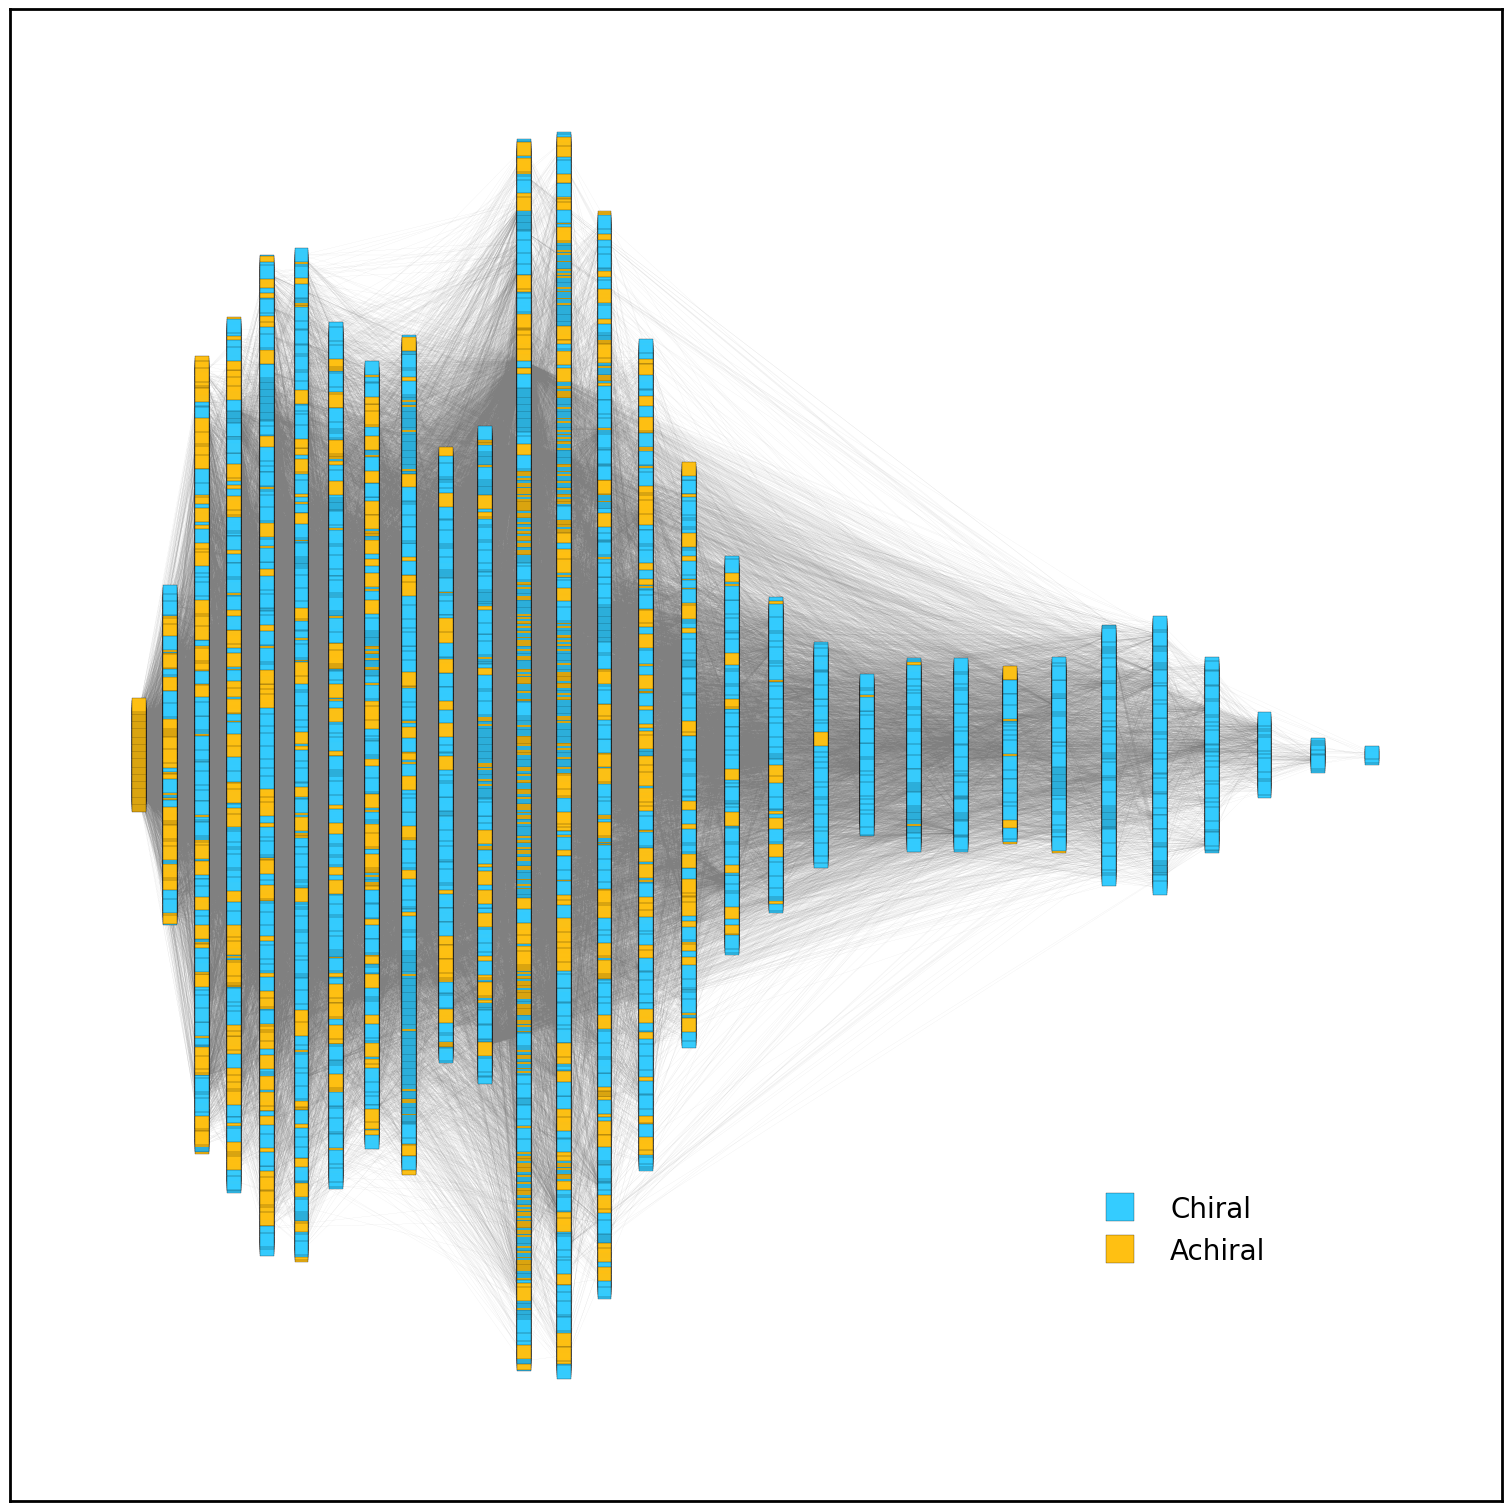

In [25]:
fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G1.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()),  
                edgecolors='k', width=0.03, arrows=False,
                linewidths=0.2, node_size=100, node_shape='s', alpha=0.99,
                with_labels=False)

plt.legend(loc='lower right', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

## Random Seed Set Expansions

In [26]:
chiral_color = "#34CCFF"
achiral_color = "#FFC012"
mixed_color = "green"

### Get X random seed sets, both chiral & achiral
n_iter = 100
min_ss_size = 2
max_ss_size = 10

randAchiral_results = dict()
randChiral_results = dict()
random_achiral_seeds = dict()
random_chiral_seeds = dict()
for random_ss_size in range(min_ss_size, max_ss_size+1):
    for i in range(n_iter):
        random_achiral_seeds[f"Random_{random_ss_size}_{i}"] = getRandomSeedSet(
            keggC_df, random_ss_size, chirality="achiral")
        random_chiral_seeds[f"Random_{random_ss_size}_{i}"] = getRandomSeedSet(
            keggC_df, random_ss_size, chirality="chiral")

print(f"- Expanding {n_iter*(max_ss_size-min_ss_size+1)} Achiral Seed Sets -")
achiral_full_chiral_CpdCount = list()
achiral_full_achiral_CpdCount = list()
achiral_full_RxnCount = list()
for name, seeds in tqdm(random_achiral_seeds.items(), total=n_iter*(max_ss_size-min_ss_size+1)):
    randAchiral_results = expand_from_seed_set(
        seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
    def result_to_df(key: str, to_apply):
        return pd.concat(
            {key: randAchiral_results[key].apply(to_apply)}, axis=1)
    
    ### Process expansion (including chiral %s at each step & heavy atom count)
    achiral_full_chiral_CpdCount.append(
            getCpdCount(randAchiral_results["cps"],
                        keggC_df,
                        ischiral_flag=True)[0].to_list())
    achiral_full_achiral_CpdCount.append(
            getCpdCount(randAchiral_results["cps"],
                        keggC_df,
                        ischiral_flag=False)[0].to_list())
    summaries = {
        'reaction count':
            result_to_df(key='rns', to_apply=lambda x: x.sum()),
    }
    achiral_full_RxnCount.append(summaries["reaction count"]["rns"].tolist())
    
print(f"- Expanding {n_iter*(max_ss_size-min_ss_size+1)} Chiral Seed Sets -")
chiral_full_chiral_CpdCount = list()
chiral_full_achiral_CpdCount = list()
chiral_full_RxnCount = list()
for name, seeds in tqdm(random_chiral_seeds.items(), total=n_iter*(max_ss_size-min_ss_size+1)):
    randChiral_results = expand_from_seed_set(
        seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
    def result_to_df(key: str, to_apply):
        return pd.concat(
            {key: randChiral_results[key].apply(to_apply)}, axis=1)
    
    chiral_full_chiral_CpdCount.append(
            getCpdCount(randChiral_results["cps"],
                        keggC_df,
                        ischiral_flag=True)[0].to_list())
    chiral_full_achiral_CpdCount.append(
            getCpdCount(randChiral_results["cps"],
                        keggC_df,
                        ischiral_flag=False)[0].to_list())
    summaries = {
        'reaction count':
            result_to_df(key='rns', to_apply=lambda x: x.sum()),
    }
    chiral_full_RxnCount.append(summaries["reaction count"]["rns"].tolist())

- Expanding 900 Achiral Seed Sets -


100%|██████████| 900/900 [12:14<00:00,  1.22it/s]


- Expanding 900 Chiral Seed Sets -


100%|██████████| 900/900 [34:09<00:00,  2.28s/it]


In [27]:
chiral_avg_cpd_scope = list()
achiral_avg_cpd_scope = list()
chiral_avg_rxn_scope = list()
achiral_avg_rxn_scope = list()

offset = 0
for random_ss_size in range(min_ss_size, max_ss_size+1):
    chiral_cpd_scope = list()
    achiral_cpd_scope = list()
    chiral_rxn_scope = list()
    achiral_rxn_scope = list()
    for i in range(n_iter):
        chiral_cpd_scope.append(chiral_full_chiral_CpdCount[i+offset][-1] + chiral_full_achiral_CpdCount[i+offset][-1])
        achiral_cpd_scope.append(achiral_full_chiral_CpdCount[i+offset][-1] + achiral_full_achiral_CpdCount[i+offset][-1])
        chiral_rxn_scope.append(chiral_full_RxnCount[i+offset][-1])
        achiral_rxn_scope.append(achiral_full_RxnCount[i+offset][-1])

    chiral_avg_cpd_scope.append(np.mean(chiral_cpd_scope))
    achiral_avg_cpd_scope.append(np.mean(achiral_cpd_scope))
    chiral_avg_rxn_scope.append(np.mean(chiral_rxn_scope))    
    achiral_avg_rxn_scope.append(np.mean(achiral_rxn_scope))

    offset += n_iter


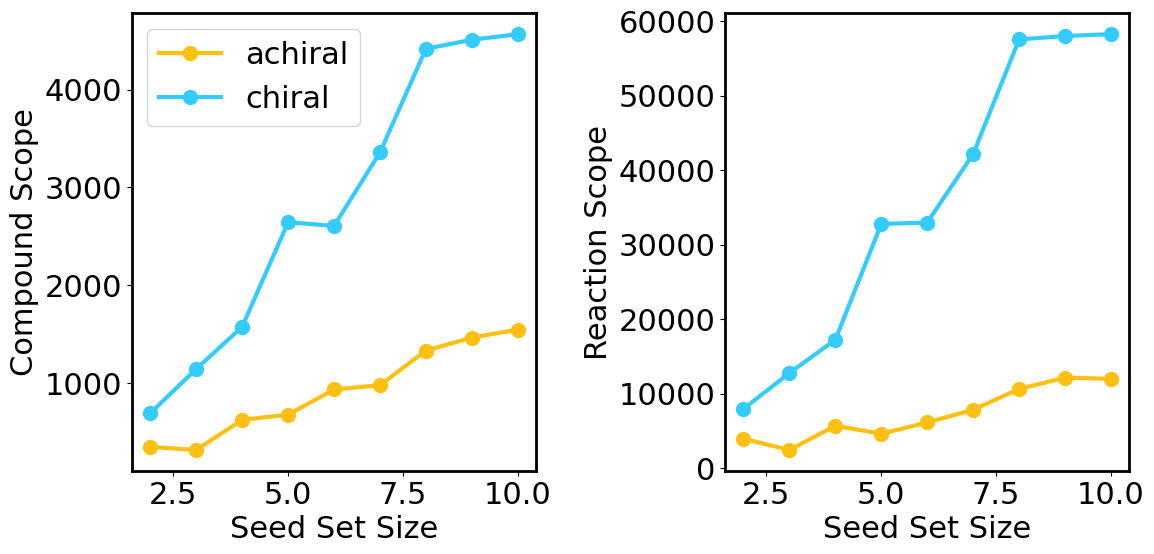

In [28]:
plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

## Cpd scope
ax1 = plt.subplot(gs[0,0])
ax1.plot(np.arange(min_ss_size,max_ss_size+1,1), achiral_avg_cpd_scope, color=achiral_color, label="achiral", 
         marker="o", linewidth=3, markersize=10)
ax1.plot(np.arange(min_ss_size,max_ss_size+1,1), chiral_avg_cpd_scope, color=chiral_color, label="chiral", 
         marker="o", linewidth=3, markersize=10)

ax1.legend()
ax1.set_xlabel("Seed Set Size")
ax1.set_ylabel("Compound Scope")

## Rxn scope
ax2 = plt.subplot(gs[0,1])
ax2.plot(np.arange(min_ss_size,max_ss_size+1,1), achiral_avg_rxn_scope, color=achiral_color, label="achiral", 
         marker="o", linewidth=3, markersize=10)
ax2.plot(np.arange(min_ss_size,max_ss_size+1,1), chiral_avg_rxn_scope, color=chiral_color, label="chiral", 
         marker="o", linewidth=3, markersize=10)

ax2.set_xlabel("Seed Set Size")
ax2.set_ylabel("Reaction Scope")

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")

fig_count+=1

In [29]:
def ridgeline_plots(full_chiral_cpdCount, full_achiral_CpdCount, l, min_ss_size, max_ss_size, n_iter):
  #Convert dataframes into appropriate style
  df_ridgeline = pd.DataFrame(columns=["n","c"])

  sizes = []
  labels = []
  offset = 0
  for random_ss_size in range(min_ss_size, max_ss_size+1):
    for i in range(n_iter):
      sizes.append(full_chiral_cpdCount[i+offset][-1] + full_achiral_CpdCount[i+offset][-1])
      labels.append(str(random_ss_size))
    offset += n_iter

  df_ridgeline["n"] = sizes
  df_ridgeline["c"] = labels

  #find the log of each expansion
  df_ridgeline["n"] = pd.to_numeric(df_ridgeline["n"])
  with np.errstate(divide='ignore'):
      df_ridgeline["n"] = np.log(df_ridgeline["n"]) #.apply(np.log())

  sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

  #color palette (first number is the number of rows in the plot)
  pal = sns.cubehelix_palette(9, rot=1, light=0.9) 

  #Grid graphing
  grid = sns.FacetGrid(df_ridgeline, row="c", hue="c", aspect=15, height=1, palette=pal)

  #grid setup
  grid.map(sns.kdeplot, "n", clip_on=False, fill=True, alpha=1, lw=1.5, bw_method=.2)
  grid.map(sns.kdeplot, "n", clip_on=False, color="w", lw=2, bw_method=.2)
  grid.map(plt.axhline, y=0, lw=2, clip_on=False)

  # Define and use a simple function to label the plot in axes coordinates
  def label(x, color, label):
      ax = plt.gca()
      ax.text(0, .2, label, size=20, fontweight="bold", color=color,
              ha="left", va="center", transform=ax.transAxes)
      
  grid.map(label, "n")

  # Set the subplots to overlap
  grid.figure.subplots_adjust(hspace=-.25)

  # Remove axes details that don't play well with overlap
  grid.set_titles("")
  grid.set_ylabels("")
  grid.set(yticks=[])
  grid.despine(bottom=True, left=True)

  plt.title("Expanded Network Distribution: " + l, pad=500, fontweight="bold", size=30)
  plt.ylabel("Seed Set Size", labelpad=20, position=(0,20), size=20)
  plt.xlabel("Log of expanded network size", size=20)

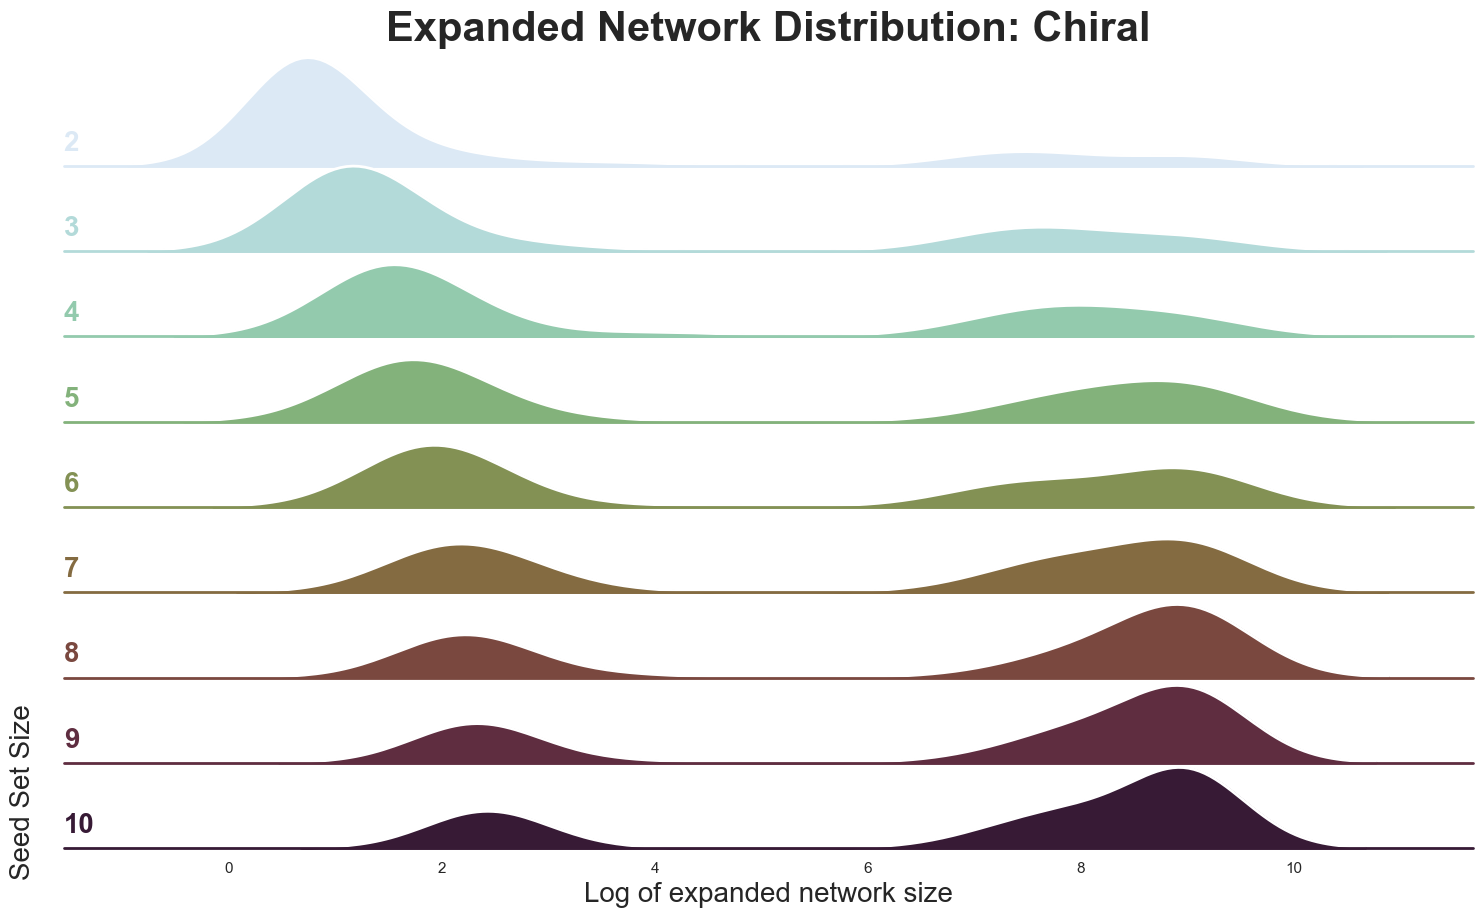

In [30]:
ridgeline_plots(chiral_full_chiral_CpdCount, chiral_full_achiral_CpdCount, "Chiral", min_ss_size, max_ss_size, n_iter)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

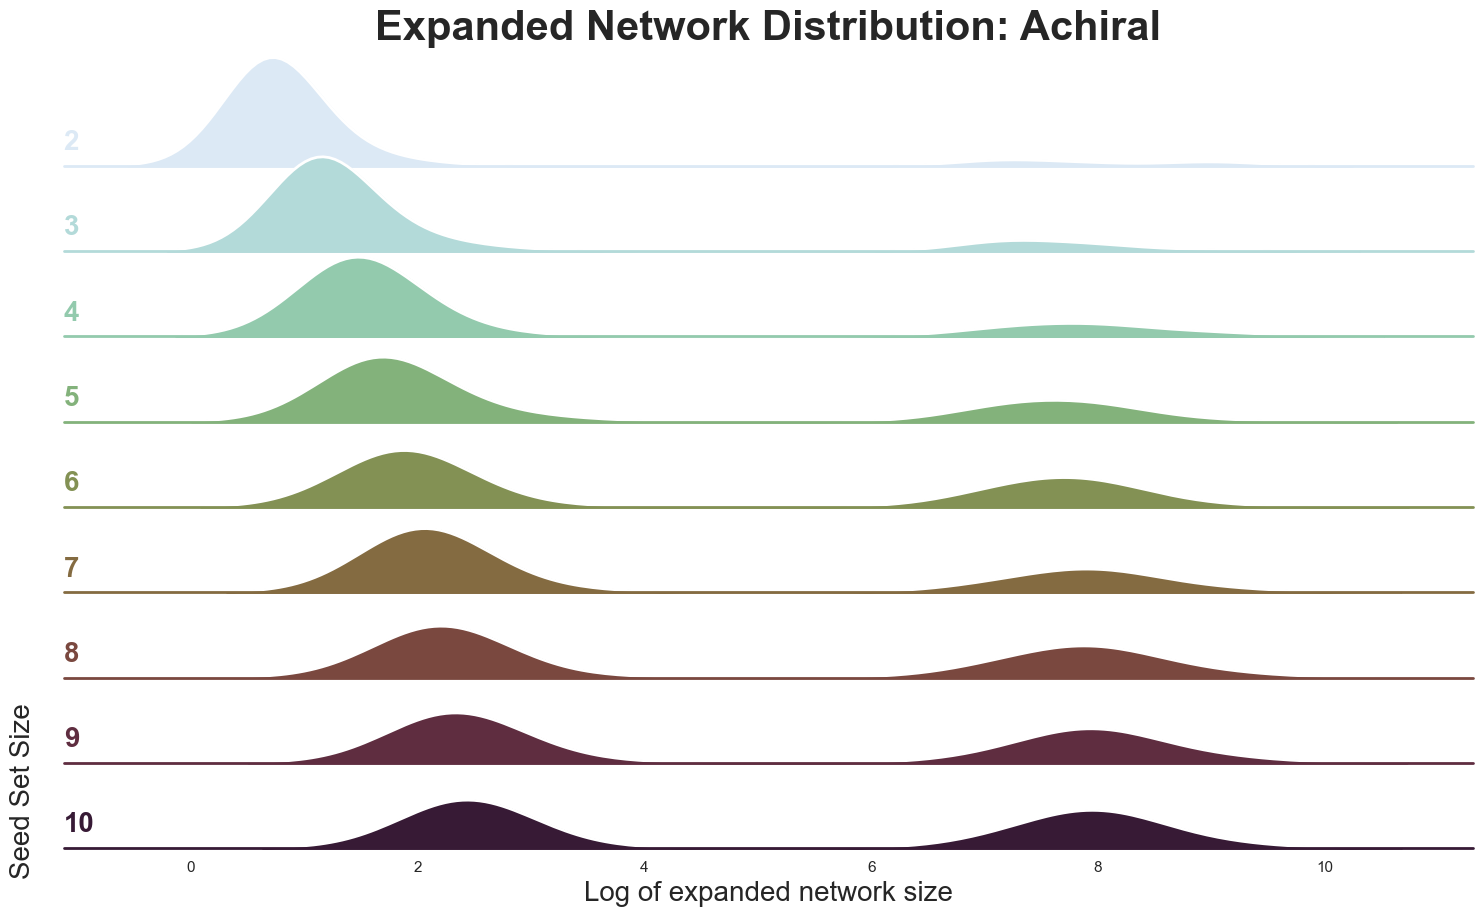

In [31]:
ridgeline_plots(achiral_full_chiral_CpdCount, achiral_full_achiral_CpdCount, "Achiral", min_ss_size, max_ss_size, n_iter)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

### Scope Histogram

Histogram showing expansion scopes put together (separated by chiral/achiral, but otherwise alltogether)

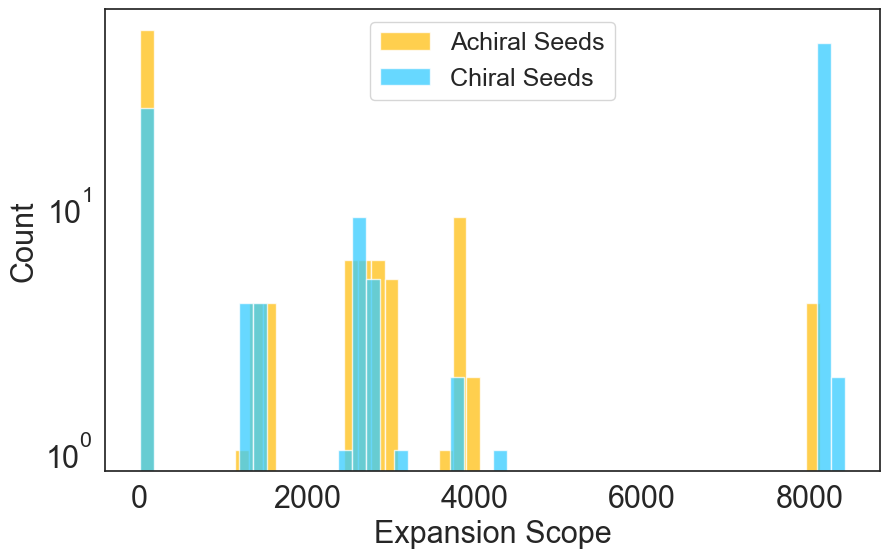

In [32]:
fig, ax = plt.subplots(figsize=(10,6))

ax.hist(achiral_cpd_scope, bins=50, color=achiral_color, label="Achiral Seeds", alpha=0.75)
ax.hist(chiral_cpd_scope, bins=50, color=chiral_color, label="Chiral Seeds", alpha=0.75)

ax.set_yscale("log")
ax.set_xlabel("Expansion Scope", fontsize=22)
ax.set_ylabel("Count", fontsize=22)
ax.tick_params(axis='both', which='both', labelsize=22)

plt.legend(facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
plt.show()
fig_count+=1

## Full Seed Set Permutations

Permute the seed set in a few ways:
- 20% dropout (1000 iterations)
- Size (drop increasing numbers of heavy atoms)

And get the following results:
- avg chiral order parameter at each step (similar to random expansions in manuscript)
- scope
- chiral/achiral crossover 

In [33]:
seed_name = "JM|G24|G17|TW"
rxn_db = "../../lets-get-kegg/Data/atlas_kegg_processed_merged_deduped.csv.zip"
max_generation = 1000 #Arbitrarily large 
n_iter = 1000

dropout_chiral_count = list()
dropout_achiral_count = list()
sizefilter_chiral_count = list()
sizefilter_achiral_count = list()

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))
compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]

print("-- Dropout Expansions --")
for i in tqdm(range(n_iter)):
    ### 49 is 80% of 61 (size of "JM|G24|G17|TW" seed set)
    seed_sets = {
        i: seed_scope.query('Source.str.contains("' + i + '")').sample(49).index
        for i in seed_groups
    }
    for name, seeds in seed_sets.items():
        randAchiral_results = expand_from_seed_set(
            seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
        dropout_chiral_count.append(
                getCpdCount(randAchiral_results["cps"],
                            keggC_df,
                            ischiral_flag=True)[0].to_list())
        dropout_achiral_count.append(
                getCpdCount(randAchiral_results["cps"],
                            keggC_df,
                            ischiral_flag=False)[0].to_list())
        
seed_scope = seed_scope.merge(keggC_df, left_on="Compound_id", right_on="compound_id")
seed_scope = seed_scope[seed_scope["Source"] != "LUCA"] #Remove LUCA from heavy atom filtering
seed_scope.set_index("compound_id", inplace=True)
unique_heavy_atoms = list(set(seed_scope["n_heavy_atoms"]))
unique_heavy_atoms.reverse()
print("-- Heavy Atom Filter Expansions --")
for heavy_atom in unique_heavy_atoms:
    if heavy_atom > 0:
        print(f"- Expanding seeds with less than {heavy_atom} heavy atoms -")
        seed_scope_filtered = seed_scope[seed_scope["n_heavy_atoms"] < heavy_atom]
        seed_sets = {
            i: seed_scope_filtered.query('Source.str.contains("' + i + '")').index
            for i in seed_groups
        }
        for name, seeds in seed_sets.items():
            heavyAtomSampling_results = expand_from_seed_set(
                seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
            sizefilter_chiral_count.append(
                    getCpdCount(heavyAtomSampling_results["cps"],
                                keggC_df,
                                ischiral_flag=True)[0].to_list())
            sizefilter_achiral_count.append(
                    getCpdCount(heavyAtomSampling_results["cps"],
                                keggC_df,
                                ischiral_flag=False)[0].to_list())


-- Dropout Expansions --


100%|██████████| 1000/1000 [1:37:15<00:00,  5.84s/it]


-- Heavy Atom Filter Expansions --
- Expanding seeds with less than 12 heavy atoms -
- Expanding seeds with less than 10 heavy atoms -
- Expanding seeds with less than 9 heavy atoms -
- Expanding seeds with less than 8 heavy atoms -
- Expanding seeds with less than 7 heavy atoms -
- Expanding seeds with less than 6 heavy atoms -
- Expanding seeds with less than 5 heavy atoms -
- Expanding seeds with less than 4 heavy atoms -
- Expanding seeds with less than 3 heavy atoms -
- Expanding seeds with less than 2 heavy atoms -
- Expanding seeds with less than 1 heavy atoms -


In [34]:
dropout_chiralPercentage = []
dropout_avg_percentages_chiral = []
dropout_std_percentages_chiral = []
dropout_scopes = []
dropout_crossover_steps = []

sizefilter_chiralPercentage = []
sizefilter_avg_percentages_chiral = []
sizefilter_std_percentages_chiral = []
sizefilter_scopes = []
sizefilter_crossover_steps = []
sizefilter_seedSizes = []

# Scopes
for i in range(len(dropout_chiral_count)):
    dropout_scopes.append(dropout_chiral_count[i][-1] + dropout_achiral_count[i][-1])

for i in range(len(sizefilter_chiral_count)):
    sizefilter_scopes.append(sizefilter_chiral_count[i][-1] + sizefilter_achiral_count[i][-1])

print(f"Dropout Scope Stats\n\tAverage: {round(np.mean(dropout_scopes), 3)}\n\tStd: {round(np.std(dropout_scopes), 3)}")
print(f"Size Filter Scope Stats\n\tAverage: {round(np.mean(sizefilter_scopes), 3)}\n\tStd: {round(np.std(sizefilter_scopes), 3)}")

for i in range(len(dropout_chiral_count)):
    dropout_chiralPercentage.append(
        get_ChiralPercentage(np.cumsum(dropout_chiral_count[i]),
                             np.cumsum(dropout_achiral_count[i])))
    
for i in range(len(sizefilter_chiral_count)):
    sizefilter_chiralPercentage.append(
        get_ChiralPercentage(np.cumsum(sizefilter_chiral_count[i]),
                             np.cumsum(sizefilter_achiral_count[i])))
    
for i in range(len(dropout_chiral_count)):
    chiral_cumcpd_count = list(np.cumsum(dropout_chiral_count[i]))
    achiral_cumcpd_count = list(np.cumsum(dropout_achiral_count[i]))

    for j in range(len(chiral_cumcpd_count)):
        if chiral_cumcpd_count[j] >= achiral_cumcpd_count[j]:
            dropout_crossover_steps.append(j)
            break

for i in range(len(sizefilter_chiral_count)):
    chiral_cumcpd_count = list(np.cumsum(sizefilter_chiral_count[i]))
    achiral_cumcpd_count = list(np.cumsum(sizefilter_achiral_count[i]))

    for j in range(len(chiral_cumcpd_count)):
        if chiral_cumcpd_count[j] >= achiral_cumcpd_count[j]:
            sizefilter_crossover_steps.append(j)
            break

print(f"Dropout Crossover Stats\n\tAverage: {round(np.mean(dropout_crossover_steps), 3)}\n\tStd: {round(np.std(dropout_crossover_steps), 3)}")
print(f"Size Filter Crossover Stats\n\tAverage: {round(np.mean(sizefilter_crossover_steps), 3)}\n\tStd: {round(np.std(sizefilter_crossover_steps), 3)}")
                      
# Chiral percentages
for i in range(max_generation):
    percentages = []
    for result in dropout_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])
    dropout_avg_percentages_chiral.append(np.mean(percentages))
    dropout_std_percentages_chiral.append(np.std(percentages))

for i in range(max_generation):
    percentages = []
    for result in sizefilter_chiralPercentage:
        if len(result) > i:
            percentages.append(result[i])
    sizefilter_avg_percentages_chiral.append(np.mean(percentages))
    sizefilter_std_percentages_chiral.append(np.std(percentages))

for i in range(len(sizefilter_chiral_count)):
    sizefilter_seedSizes.append( sizefilter_chiral_count[i][0] + sizefilter_achiral_count[i][0])

### Original Expansion
original_percent_chiral = []
for i in range(len(cum_chiral_count)):
    original_percent_chiral.append(cum_chiral_count[i] / (cum_chiral_count[i] + cum_achiral_count[i]))

Dropout Scope Stats
	Average: 8574.095
	Std: 400.676
Size Filter Scope Stats
	Average: 6215.364
	Std: 2890.703
Dropout Crossover Stats
	Average: 5.248
	Std: 0.717
Size Filter Crossover Stats
	Average: 8.1
	Std: 2.508


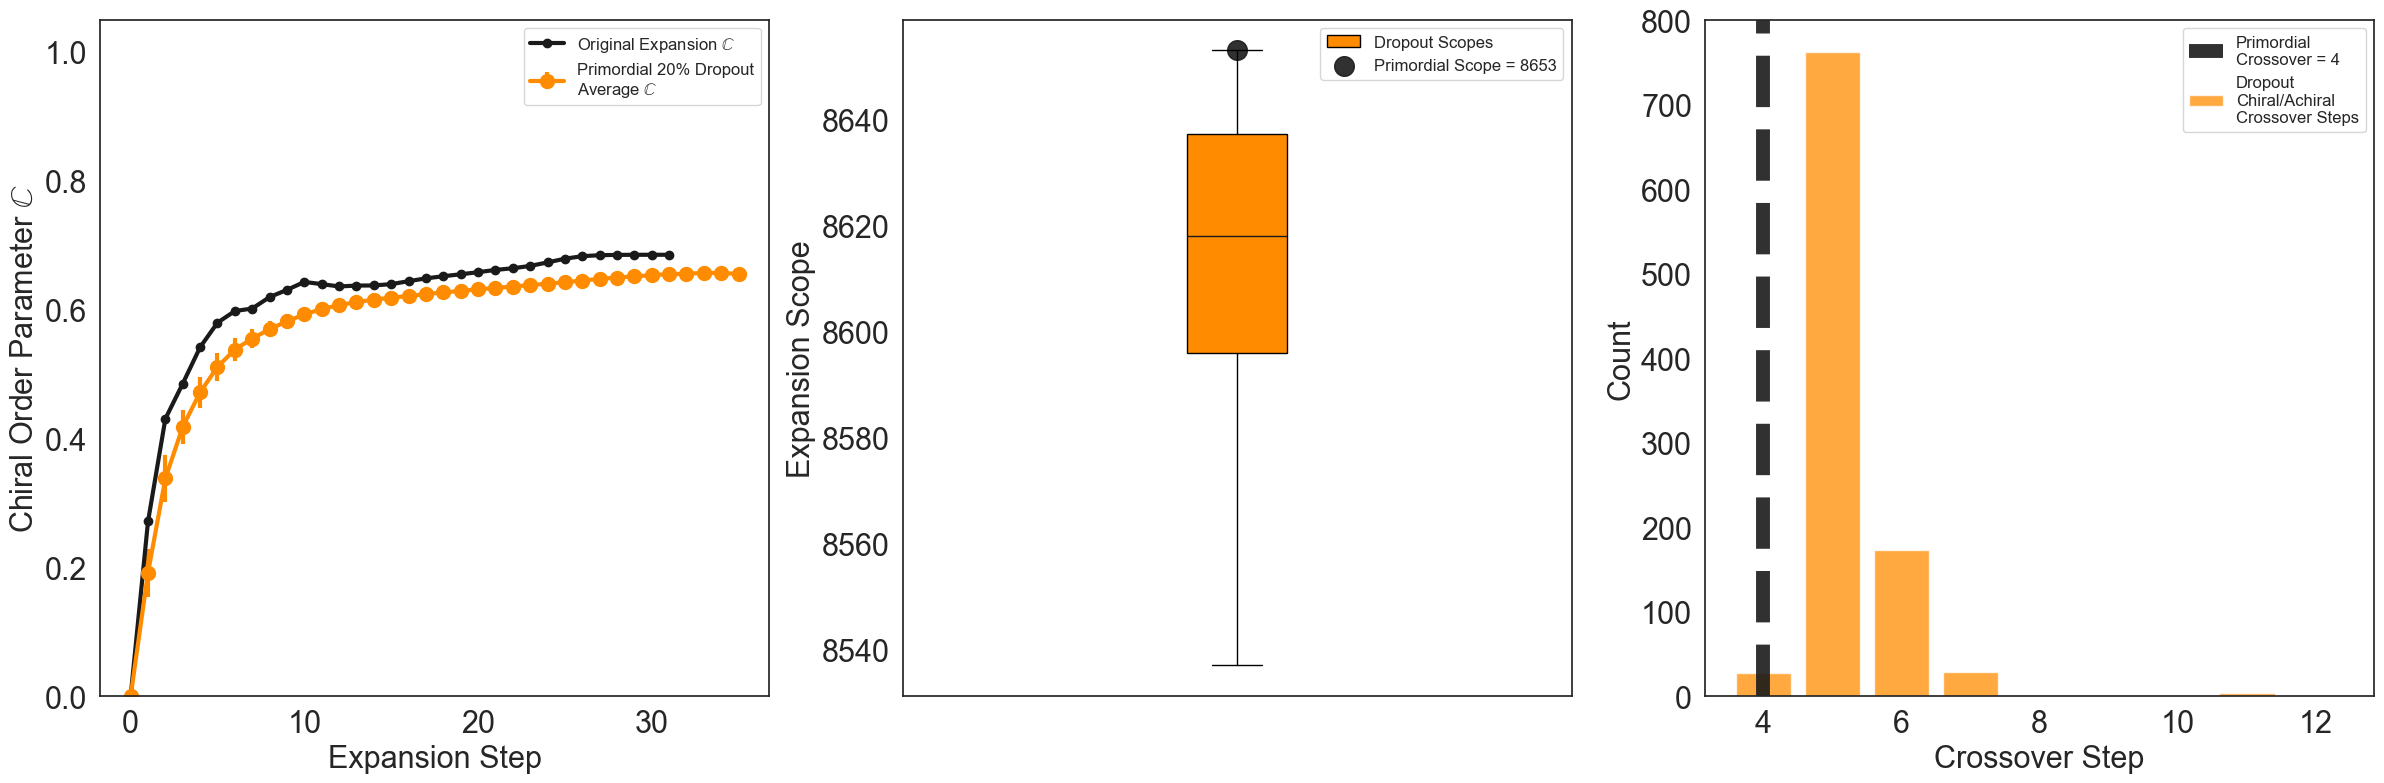

In [35]:
dropout_color = "darkorange"

plt.figure(figsize=(24,8))
gs = gridspec.GridSpec(1,3)

### Chiral order parameter by expansion step
ax1 = plt.subplot(gs[0,0])
# Chiral errorbar
ax1.errorbar(x=np.arange(0, len(dropout_avg_percentages_chiral), 1),
            y=dropout_avg_percentages_chiral,
            yerr=dropout_std_percentages_chiral,
            color=dropout_color,
            marker="o",
            linewidth=3,
            markersize=10,
            label="Primordial 20% Dropout\nAverage $\mathbb{C}$")

ax1.plot(original_percent_chiral,
        "o-",
        color="k",
        linewidth=3,
        label="Original Expansion $\mathbb{C}$")

ax1.set_ylim([0, 1.05])
ax1.set_xlabel("Expansion Step", fontsize=22)
ax1.set_ylabel("Chiral Order Parameter $\mathbb{C}$", fontsize=22)
ax1.tick_params(axis='both', which='both', labelsize=22)
ax1.legend(facecolor="white", prop={"size": 12})

### Boxplot
ax2 = plt.subplot(gs[0,1])
bplot = ax2.boxplot(dropout_scopes, label="Dropout Scopes", patch_artist=True, showfliers=False)
ax2.scatter(x=1, y=cum_chiral_count[-1] + cum_achiral_count[-1], s=200, color="k", alpha=0.9, 
           label=f"Primordial Scope = {cum_chiral_count[-1] + cum_achiral_count[-1]}")

for patch, color in zip(bplot['boxes'], [dropout_color]):
    patch.set_facecolor(color)

for median in bplot['medians']:
    median.set_color('k')

ax2.set_ylabel("Expansion Scope", fontsize=22)
ax2.tick_params(axis='both', which='both', labelsize=22)
ax2.set_xticklabels("")
ax2.set_xticks([])
ax2.legend(facecolor="white", prop={"size": 12})


### Dropout crossover stats
ax3 = plt.subplot(gs[0,2])
labels, counts = np.unique(dropout_crossover_steps, return_counts=True)
ax3.bar(labels, counts, color=dropout_color, label="Dropout\nChiral/Achiral\nCrossover Steps", alpha=0.75)
ax3.axvline(x=achiral_chiral_crossover_step, color="k", lw=10, alpha=0.9, linestyle="--", label=f"Primordial\nCrossover = {achiral_chiral_crossover_step}")

ax3.set_xlabel("Crossover Step", fontsize=22)
ax3.set_ylabel("Count", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 12})

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

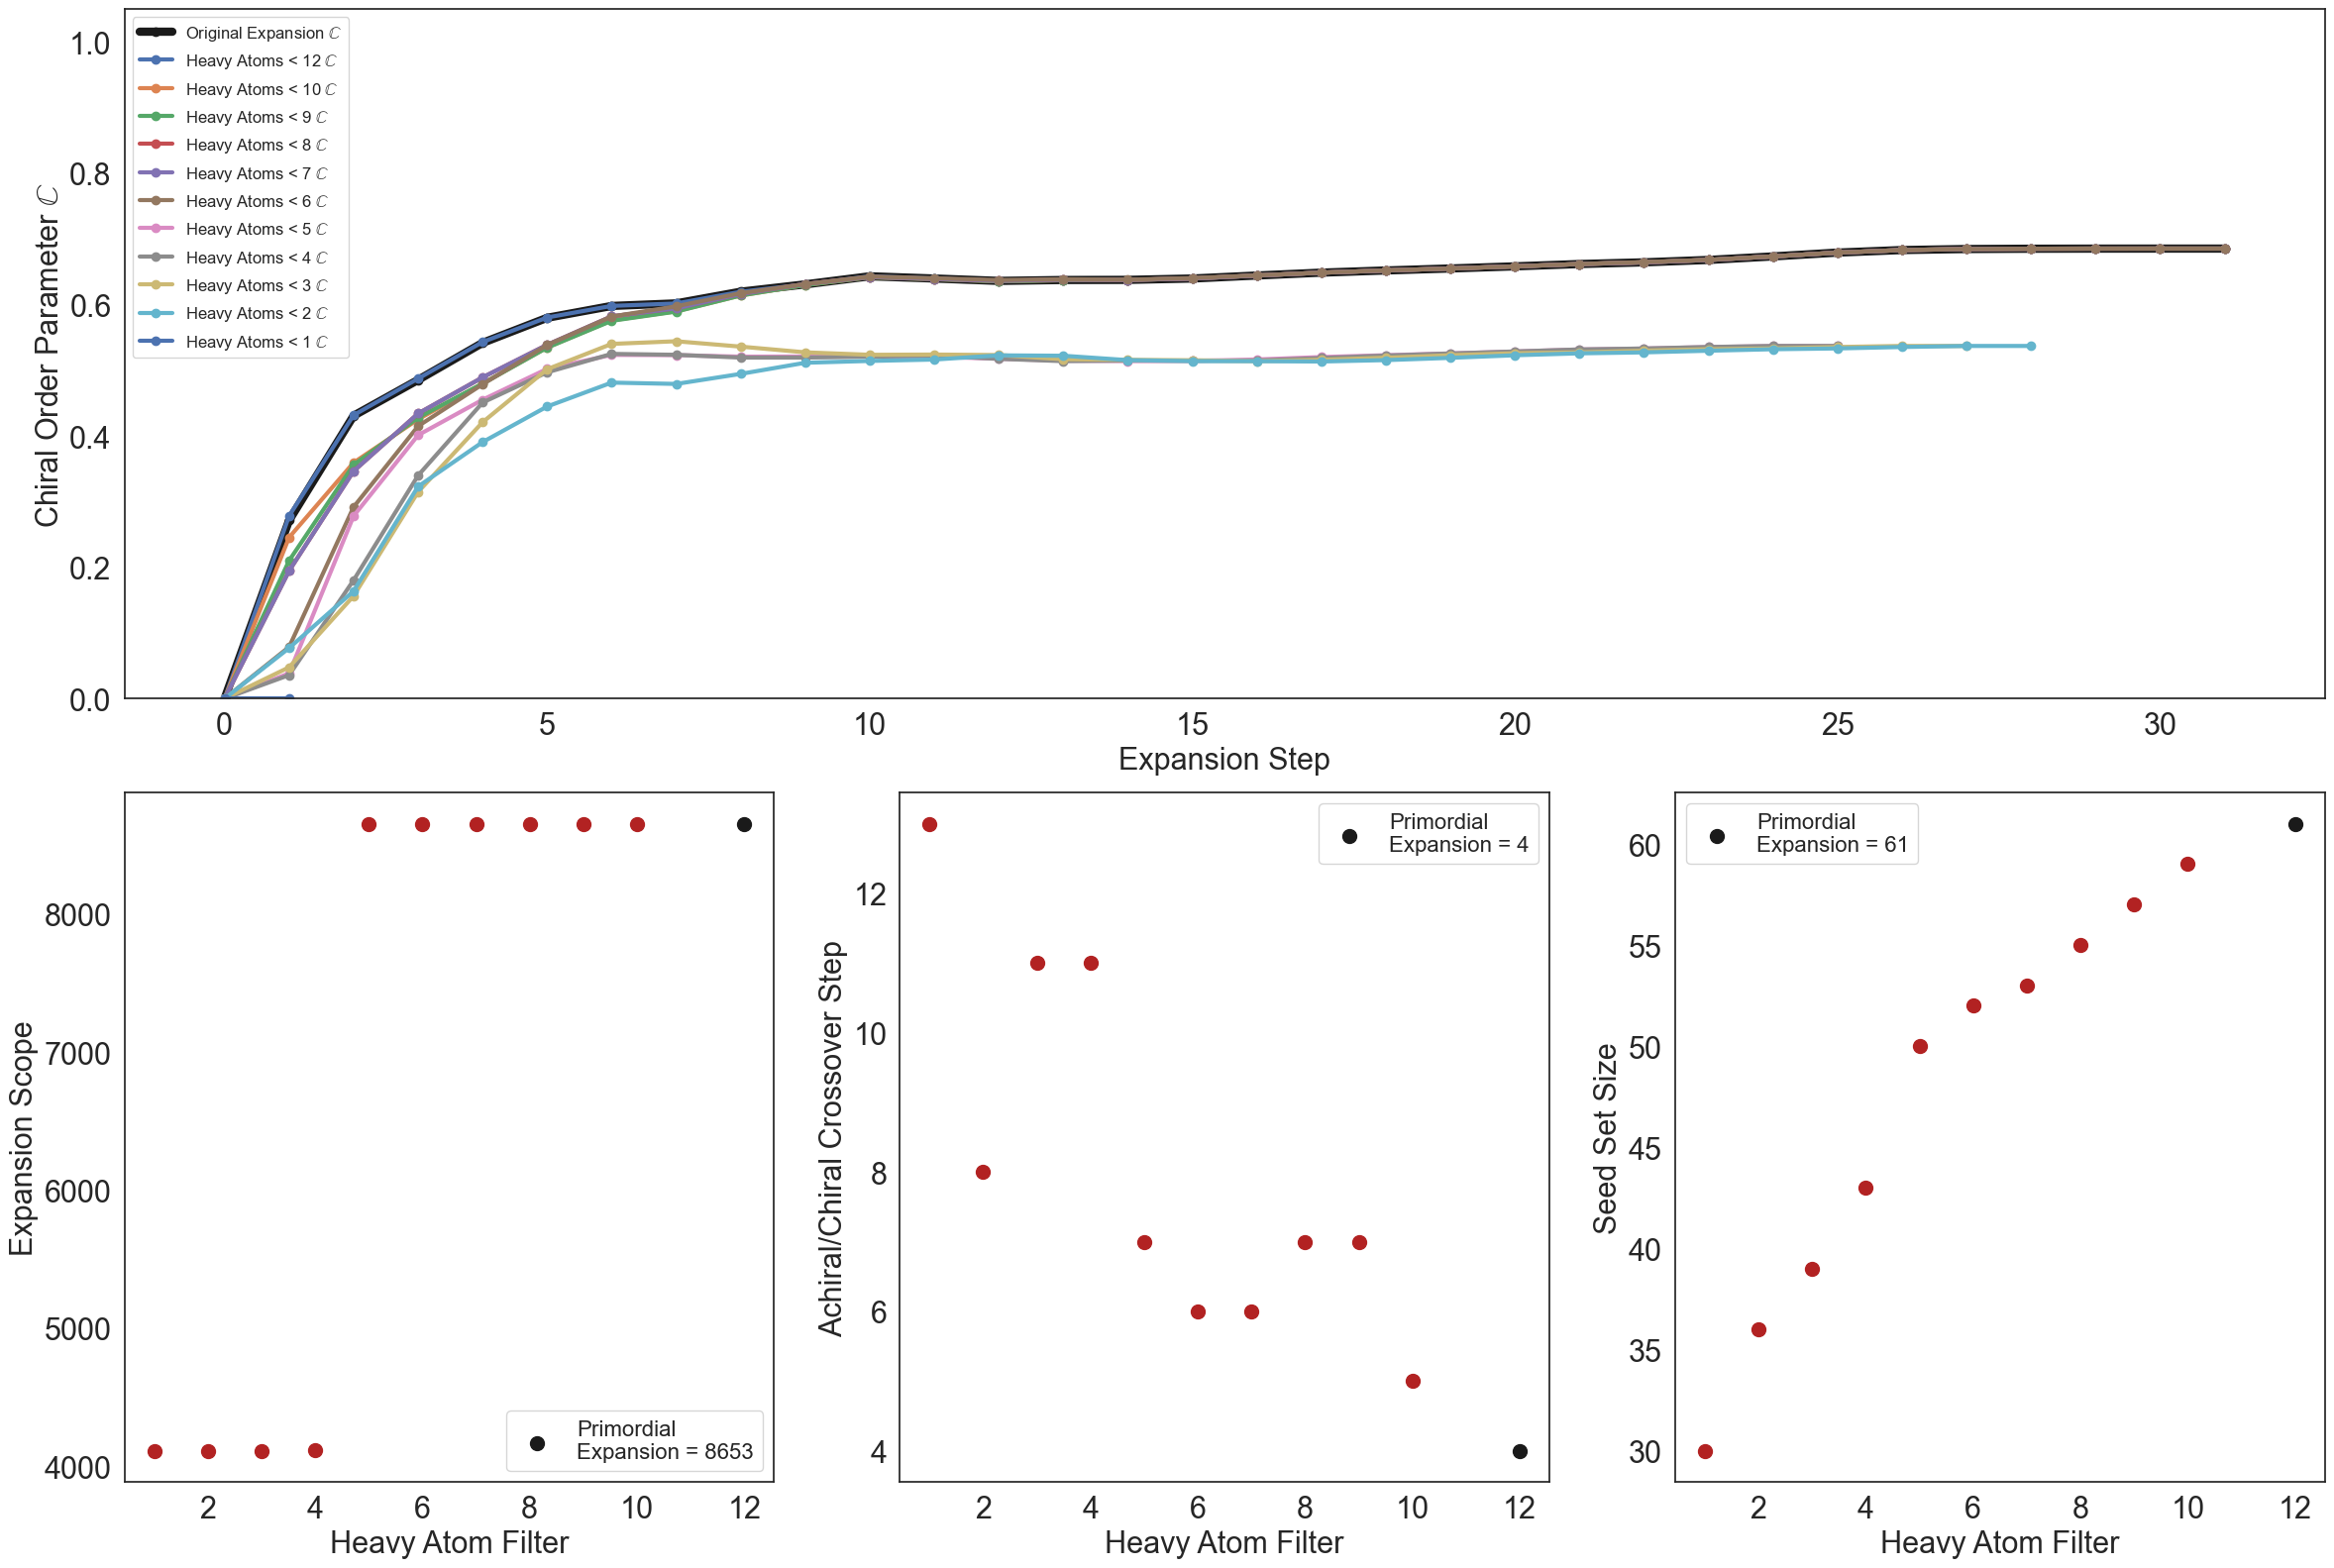

In [36]:
sizefilter_color = "firebrick"

plt.figure(figsize=(24,16))
gs = gridspec.GridSpec(2,3)

### Heavy Atom filtered expansions
ax1 = plt.subplot(gs[0,:])
ax1.plot(original_percent_chiral,
        "o-",
        color="k",
        linewidth=6,
        label="Original Expansion $\mathbb{C}$")

for i in range(len(sizefilter_chiral_count)):
    filter_chiral_percentage = []
    for j in range(len(sizefilter_chiral_count[i])):
        filter_chiral_percentage.append(sizefilter_chiral_count[i][j] / (sizefilter_chiral_count[i][j] + sizefilter_achiral_count[i][j]))
    ax1.plot(filter_chiral_percentage,
            "o-",
            linewidth=3,
            label=f"Heavy Atoms < {unique_heavy_atoms[i]}" + " $\mathbb{C}$")

ax1.set_ylim([0, 1.05])
ax1.set_xlabel("Expansion Step", fontsize=22)
ax1.set_ylabel("Chiral Order Parameter $\mathbb{C}$", fontsize=22)
ax1.tick_params(axis='both', which='both', labelsize=22)
ax1.legend(facecolor="white", prop={"size": 12})

### Expansion scopes
ax2 = plt.subplot(gs[1,0])
ax2.scatter(x=unique_heavy_atoms[1:-1], y=sizefilter_scopes[:-1], color=sizefilter_color, s=100)
ax2.scatter(x=[12], y=[cum_chiral_count[-1] + cum_achiral_count[-1]], color="k", label=f"Primordial\nExpansion = {cum_chiral_count[-1] + cum_achiral_count[-1]}", s=100)

ax2.set_ylabel("Expansion Scope", fontsize=22)
ax2.set_xlabel("Heavy Atom Filter", fontsize=22)
ax2.tick_params(axis='both', which='both', labelsize=22)
ax2.legend(facecolor="white", prop={"size": 16})

### Expansion crossovers
ax3 = plt.subplot(gs[1,1])
ax3.scatter(x=unique_heavy_atoms[1:-1], y=sizefilter_crossover_steps, color=sizefilter_color, s=100)
ax3.scatter(x=[12], y=[achiral_chiral_crossover_step], color="k", label=f"Primordial\nExpansion = {achiral_chiral_crossover_step}", s=100)

ax3.set_ylabel("Achiral/Chiral Crossover Step", fontsize=22)
ax3.set_xlabel("Heavy Atom Filter", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 16})

### Seed Set size per filter
ax3 = plt.subplot(gs[1,2])
ax3.scatter(x=unique_heavy_atoms[1:-1], y=sizefilter_seedSizes[:-1], color=sizefilter_color, s=100)
ax3.scatter(x=[12], y=[cum_chiral_count[0] + cum_achiral_count[0]], color="k", label=f"Primordial\nExpansion = {cum_chiral_count[0] + cum_achiral_count[0]}", s=100)

ax3.set_ylabel("Seed Set Size", fontsize=22)
ax3.set_xlabel("Heavy Atom Filter", fontsize=22)
ax3.tick_params(axis='both', which='both', labelsize=22)
ax3.legend(facecolor="white", prop={"size": 16})

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

## LUCA Expansions

In [37]:
### Adding LUCA cpds to Sample Seeds
with open("../Data/LUCA_ec_compound_unique_list_clean.json", "r") as f:
    luca_cpds = json.load(f)

temp_cpds = list(luca_cpds["Luca"])
print(f"Number of LUCA compounds in seed set: {len(temp_cpds)}")

seed_df = pd.read_csv("../Data/SampleSeeds.csv.zip", compression='zip')
for i, row in seed_df.iterrows():
    if row["Compound_id"] in (luca_cpds["Luca"]) and "LUCA" not in row["Source"]:
        source_str = row["Source"] + " LUCA"
        seed_df.at[i,'Source'] = source_str
        temp_cpds.remove(row["Compound_id"])

for new_cpd in temp_cpds:
    if new_cpd not in list(seed_df["Compound_id"]):
        seed_df.loc[len(seed_df)] = [new_cpd, 'TODO', 'LUCA', False] 

seed_df.to_csv("../Data/SampleSeeds.csv.zip", compression='zip', index=False)

seed_df = pd.read_csv("../Data/SampleSeeds.csv.zip", index_col=0, compression='zip')


Number of LUCA compounds in seed set: 438


In [38]:
#Run network expansion processing
# Seed set
seed_name = "LUCA"
rxn_db = "../../lets-get-kegg/Data/atlas_kegg_processed_merged_deduped.csv.zip"
max_generation = 1000 #Arbitrarily large 

seed_groups = [seed_name]
reaction_scope = get_sides(import_reaction_file(rxn_db))

compound_scope = set.union(*reaction_scope.stack())
seed_candidates = pd.read_csv(f'{data_folder}/SampleSeeds.csv.zip', index_col=0, compression='zip')
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seed_sets = {
    i: seed_scope.query('Source.str.contains("' + i + '")').index
    for i in seed_groups
}
print(f"- Seed Set ({seed_name}) -")

### Run network expansion on original seed set
results = dict()
for name, seeds in seed_sets.items():
    print(seeds)
    results[name] = expand_from_seed_set(seeds=seeds,
                                            reactions=reaction_scope,
                                            max_gen=max_generation)
    results[name]['bipartite_edgelist'] = make_bipartite_edgelist(
        results[name]['edge_pool'])

### Process expansion (including chiral %s at each step & heavy atom count)
def result_to_df(key: str, to_apply):
    return pd.concat(
        {i: results[i][key].apply(to_apply) for i in results.keys()}, axis=1)


summaries = {
    'compound count':
        result_to_df(key='cps', to_apply=lambda x: x.sum()),
    'reaction count':
        result_to_df(key='rns', to_apply=lambda x: x.sum()),
    'chiral compound count':
        getCpdCount(results[seed_name]["cps"], keggC_df,
                    ischiral_flag=True),
    'achiral compound count':
        getCpdCount(results[seed_name]["cps"],
                    keggC_df,
                    ischiral_flag=False),
    'chiral fraction':
        result_to_df(key='chiral_fraction', to_apply=lambda x: x),
    'chiral avg heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=True,
                                        calc="mean"),
    'achiral avg heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=False,
                                        calc="mean"),
    'chiral std heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=True,
                                        calc="std"),
    'achiral std heavy atoms':
        getHeavyAtoms_perGen_fromKegg(results[seed_name]["cps"],
                                        keggC_df,
                                        ischiral_flag=False,
                                        calc="std")
}

cum_chiral_count = summaries["chiral compound count"][0].to_list()
cum_achiral_count = summaries["achiral compound count"][0].to_list()

- Seed Set (LUCA) -
Index(['C00033', 'C00283', 'C00288', 'C00001', 'C00009', 'C00011', 'C00014',
       'C00080', 'C00022', 'C00026',
       ...
       'C20864', 'C20904', 'C20905', 'C20969', 'C21004', 'C21031', 'C21748',
       'C21749', 'C21750', 'C21751'],
      dtype='object', name='Compound_id', length=402)


In [39]:
new_chiral_count = []
new_achiral_count = []
for i in range(len(cum_chiral_count)):
    if i > 0:
        new_chiral_count.append(cum_chiral_count[i] - cum_chiral_count[i-1])
        new_achiral_count.append(cum_achiral_count[i] - cum_achiral_count[i-1])
    else:
        new_chiral_count.append(0)
        new_achiral_count.append(0)

new_total_count = [x+y for x,y in zip(new_chiral_count, new_achiral_count)]


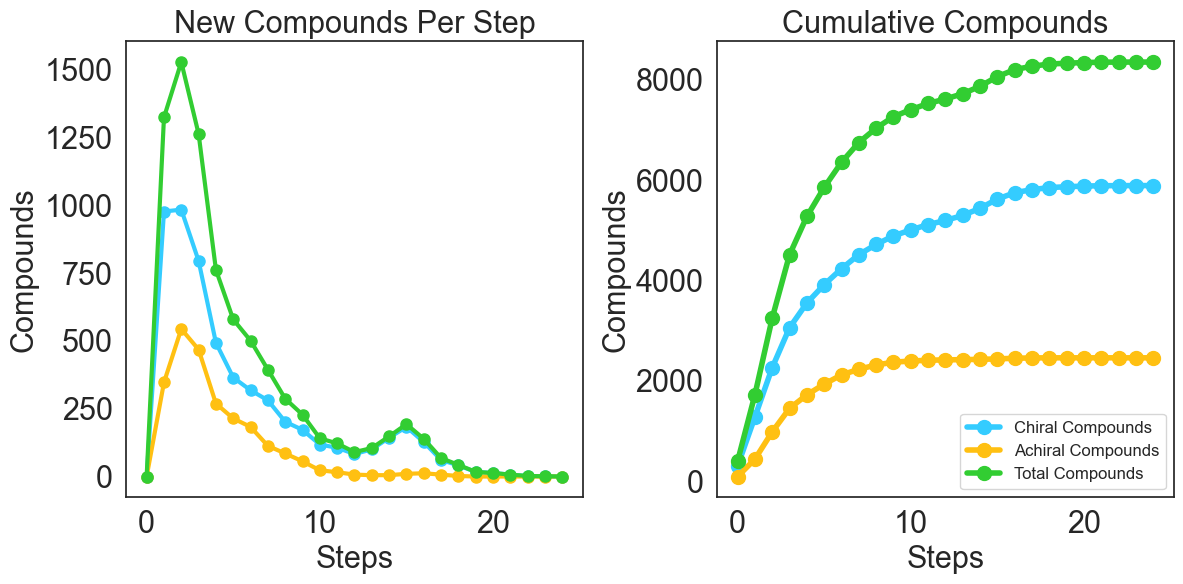

In [40]:
### LUCA Expansion plots
plt.figure(figsize=(12,6))
gs = gridspec.GridSpec(1,2)

# Plotting by new compounds
ax1 = plt.subplot(gs[0,0])

ax1.plot(new_chiral_count, color=chiral_color, marker="o", linewidth=3, markersize=8,
         label="Chiral Compounds",)
ax1.plot(new_achiral_count,  color=achiral_color, marker="o", linewidth=3, markersize=8,
         label="Achiral Compounds")
ax1.plot(np.arange(0, len(new_chiral_count), 1), new_total_count,
         color=sum_color, marker="o", linewidth=3, markersize=8, label="Total New Compounds")

ax1.set_xlabel("Steps", fontsize=22)
ax1.set_ylabel("Compounds", fontsize=22)
ax1.tick_params(axis='both', which='major', labelsize=22)
ax1.set_title("New Compounds Per Step", fontsize=22)

ax2 = plt.subplot(gs[0,1])
ax2.plot(cum_chiral_count, color=chiral_color, marker="o", linewidth=4, markersize=10,
         label="Chiral Compounds",)
ax2.plot(cum_achiral_count,  color=achiral_color, marker="o", linewidth=4, markersize=10,
         label="Achiral Compounds")
ax2.plot(np.arange(0, len(cum_chiral_count), 1), summaries["compound count"],
         color=sum_color, marker="o", linewidth=4, markersize=10, label="Total Compounds")

ax2.legend(facecolor="white", prop={"size": 12})
ax2.set_xlabel("Steps", fontsize=22)
ax2.set_ylabel("Compounds", fontsize=22)
ax2.tick_params(axis='both', which='major', labelsize=22)
ax2.set_title("Cumulative Compounds", fontsize=22)

plt.tight_layout()
plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

# Pathways

In [41]:
### Get pathway names & cpd lists from KEGG (see slack for API calls)
session = prepare_session()
pathway_cpd_links, pathway_names = get_pathway_data(session=session)
pathway_chiralPercentage = dict()
pathway_size = dict()

### Get chirality of each pathway
print("- Calculating chiral percentage of pathways -")
for pathway in tqdm(pathway_cpd_links.keys()):
    pathway_chiralPercentage[pathway], pathway_size[
        pathway] = get_chiral_percentage_fromList(
        pathway_cpd_links[pathway], keggC_df)

pathway_df = pd.DataFrame(
    [pathway_chiralPercentage, pathway_names,
        pathway_size]).transpose().dropna().sort_values(by=[0],
                                                        ascending=False)
pathway_df = pathway_df.rename(columns={
    0: "Chirality",
    1: "Name",
    2: "Size"
})

- Getting KEGG pathway-compound links -
- Getting KEGG pathway names -
- Calculating chiral percentage of pathways -


100%|██████████| 456/456 [00:00<00:00, 1003.07it/s]


In [42]:
pathway_df['ID'] = pathway_df.index
# Get color setup & information
print("- Getting color schema -")
pathway_df, chiralities, pathway_group_colors, metabolism_groups, colors, color_list = get_pathway_colors(
    pathway_df)

- Getting color schema -


In [43]:
#Hardcoding metabolic pathway subgroup names & colors

metabolism_groups = {"Carbohydrate Metabolism": [10,20,30,40,51,52,53,500,520,620,630,640,650,660,562],
                     "Glycan Biosynthesis": [510,513,512,515,514,532,534,533,531,563,601,603,604,540,542,541,550,511,571,572],
                     "Terpenoids and Polyketides": [900,902,909,904,906,905,981,908,903,281,1052,522,1051,1059,1056,1057,253,523,1054,1053,1055],
                     "Lipid Metabolism": [61,62,71,73,100,120,121,140,561,564,565,600,590,591,592,1040],
                     "Secondary Metabolite Biosynthesis": [940,945,941,944,942,943,901,403,950,960,1058,232,965,966,402,311,332,261,331,521,524,525,401,404,405,333,254,999,998,997],
                     "Nucleotide Metabolism": [230,240],
                     "Amino Acid Metabolism": [250,260,270,280,290,300,310,220,330,340,350,360,380,400],
                     "Metabolism of Other Amino Acids": [410,430,440,450,460,470,480],
                     "Cofactors and Vitamins": [730,740,750,760,770,780,785,790,670,830,860,130],
                     "Energy Metabolism": [190,195,196,710,720,680,910,920],
                     "Xenobiotics": [362,627,364,625,361,623,622,633,642,643,791,930,363,621,626,624,365,984,980,982,983]}

colors = {"Carbohydrate Metabolism": "#aa0f35", 
          "Glycan Biosynthesis": "#487c7c", 
          "Terpenoids and Polyketides": "#009ecb", 
          "Lipid Metabolism": "#abdbfc", 
          "Secondary Metabolite Biosynthesis": "#430057", 
          "Nucleotide Metabolism": "#a0a75c", 
          "Amino Acid Metabolism": "#603734",
          "Metabolism of Other Amino Acids": "#d97e43", 
          "Cofactors and Vitamins": "#313a61", 
          "Energy Metabolism": "#fdc799",
          "Xenobiotics": "#f5c500"}

pathway_group_keys = {"Carbohydrate Metabolism": 1, 
          "Glycan Biosynthesis": 2, 
          "Terpenoids and Polyketides": 3, 
          "Lipid Metabolism": 4, 
          "Secondary Metabolite Biosynthesis": 5, 
          "Nucleotide Metabolism": 6, 
          "Amino Acid Metabolism": 7,
          "Metabolism of Other Amino Acids": 8, 
          "Cofactors and Vitamins": 9, 
          "Energy Metabolism": 10,
          "Xenobiotics": 11}

color_list = ["#aa0f35", 
          "#487c7c", 
          "#009ecb", 
          "#abdbfc", 
          "#430057", 
          "#a0a75c", 
          "#603734",
          "#d97e43", 
          "#fdc799",
          "#313a61", 
          "#f5c500"]

def set_box_color(bp, color):
  plt.setp(bp['boxes'], color=color)
  plt.setp(bp['whiskers'], color=color)
  plt.setp(bp['caps'], color=color)
  plt.setp(bp['medians'], color=color)

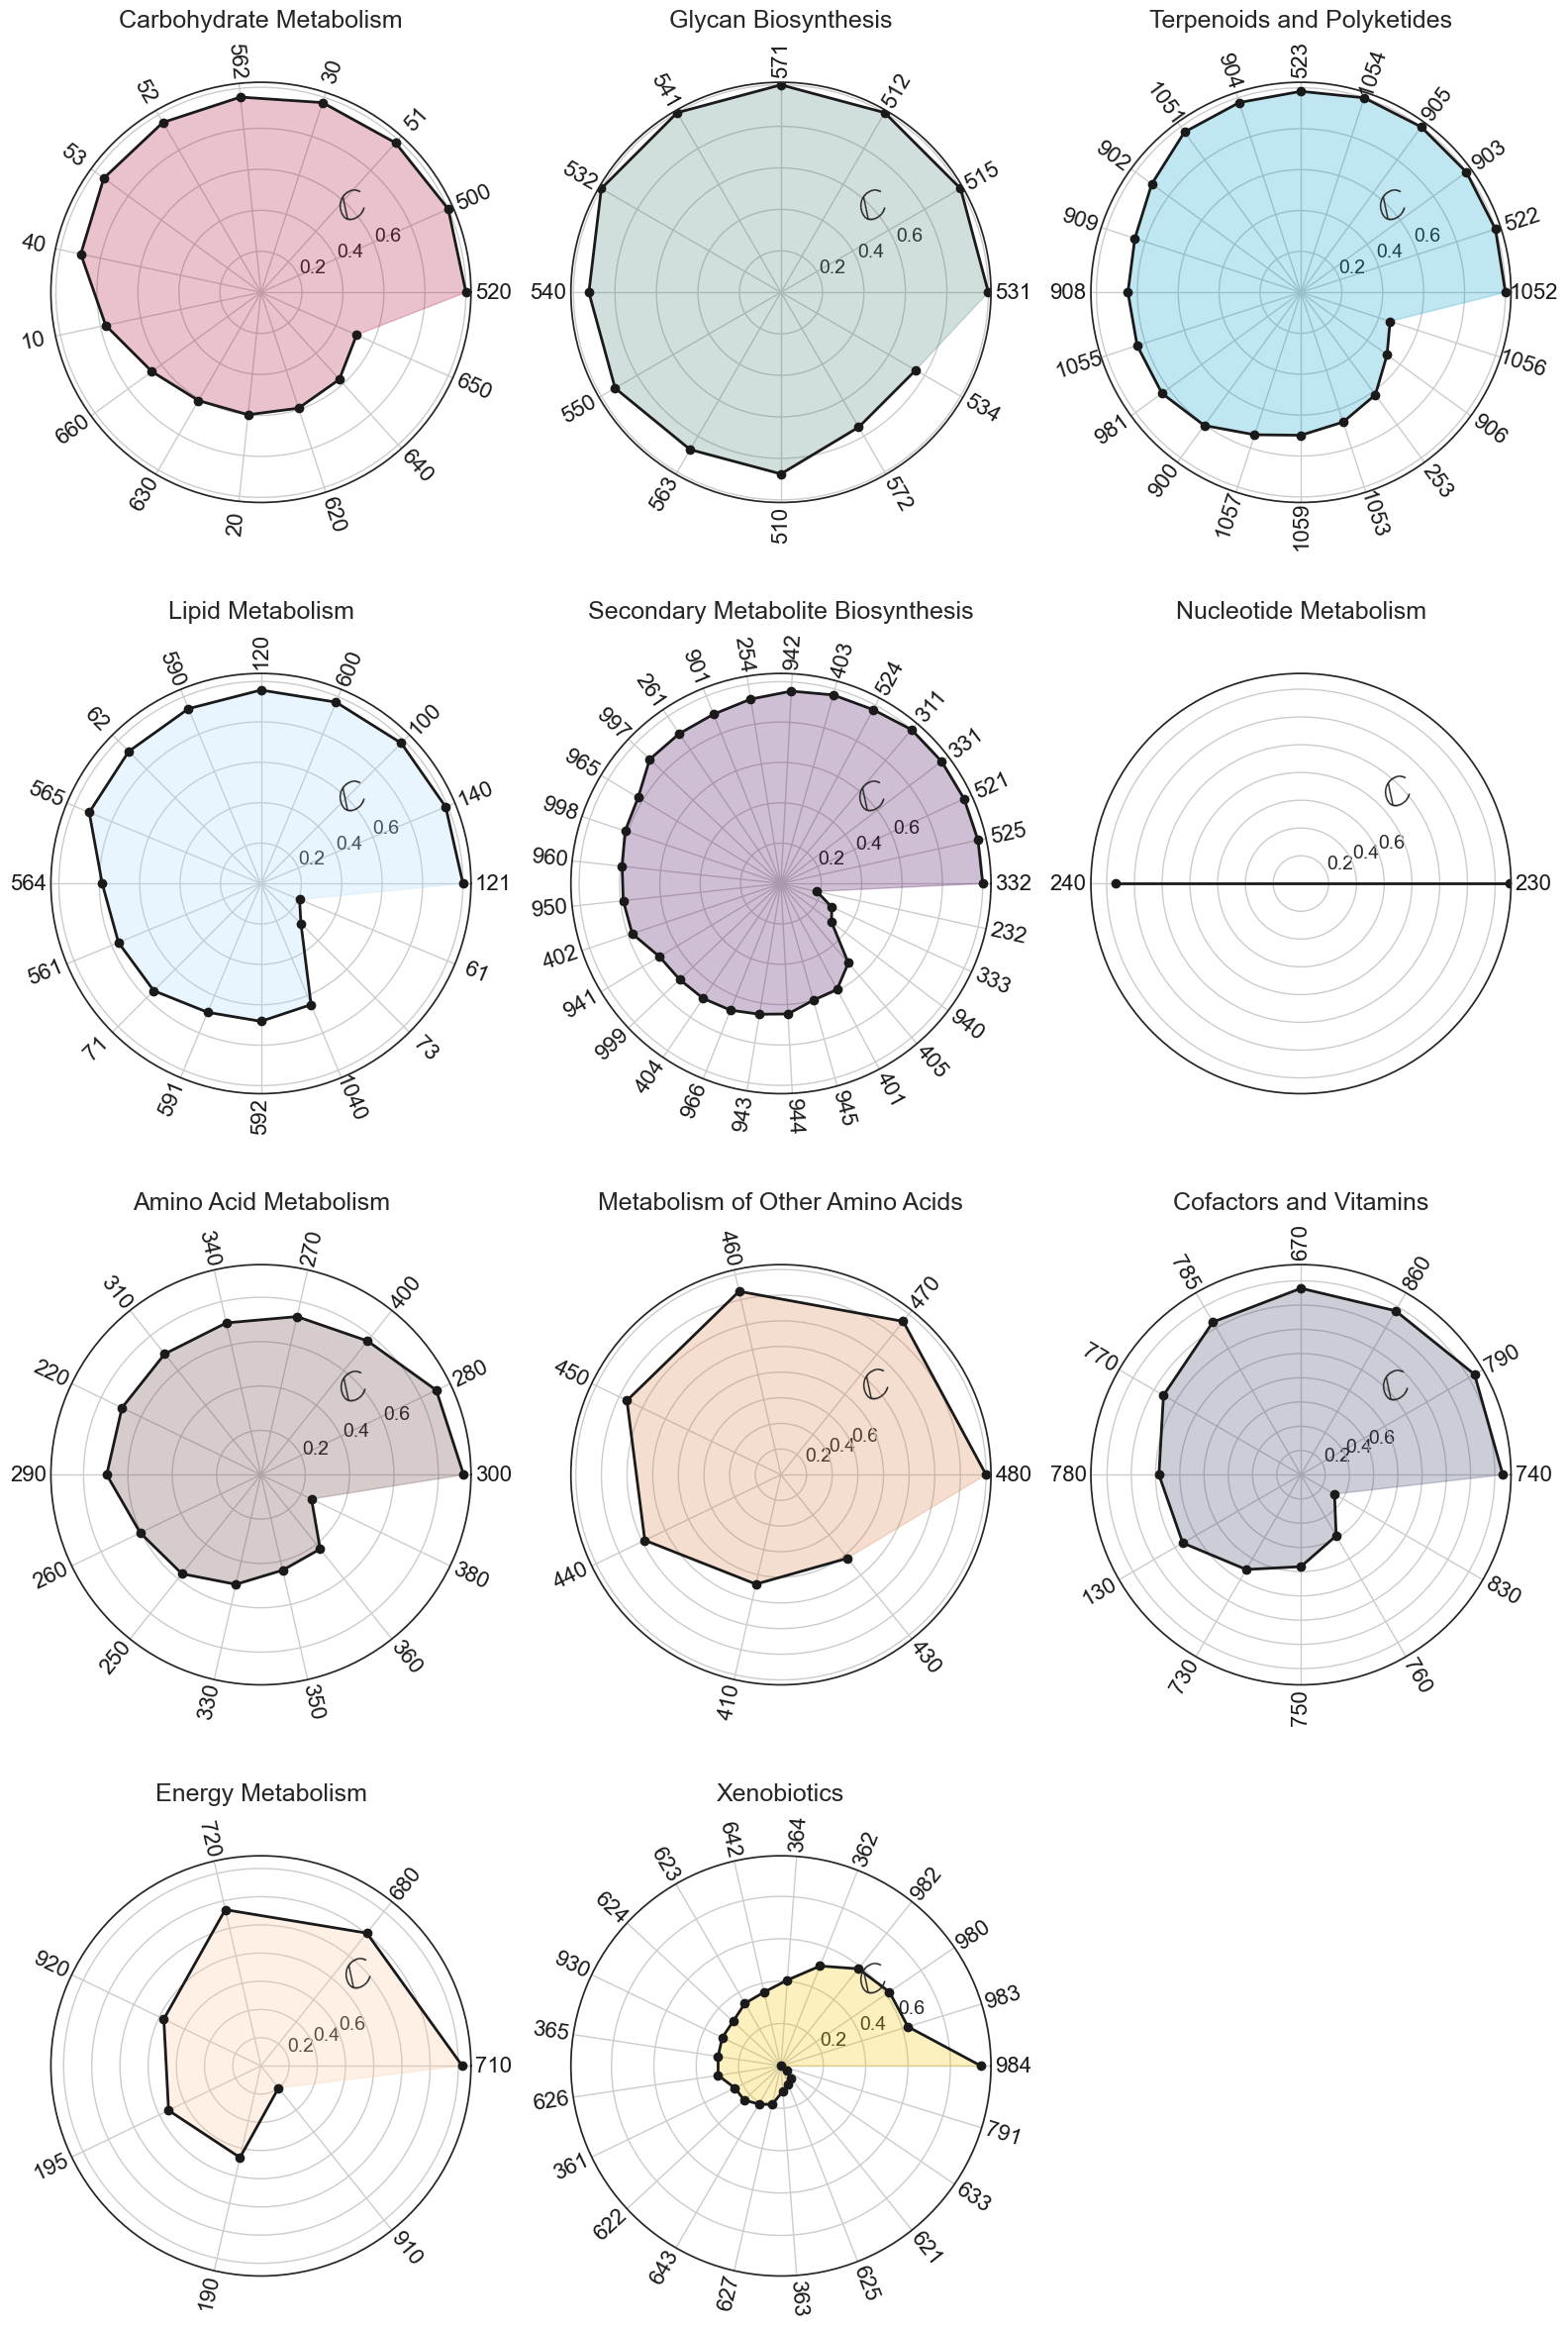

In [44]:
plt.figure(figsize=(16,24))
gs = gridspec.GridSpec(4,3)

xcount = 0
ycount = 0

for group in list(metabolism_groups.keys()):
  #Label with pathway number
  sub_df = pathway_df[pathway_df["Group"] == group]
  labels = sub_df['ID'].tolist()

  # print(labels)

  #Define each angle for plotting
  angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)
  stats = sub_df['Chirality'].tolist()
  # print(stats)

  ax = plt.subplot(gs[xcount,ycount], polar=True)
  #ax = fig.add_subplot(polar=True)
  ax.plot(angles, stats, 'o-', linewidth=2, color="k")
  ax.fill(angles, stats, alpha=0.25, color=colors[group])
  ax.set_thetagrids(angles * 180/np.pi, labels,)

  #Make all angles rotated according to placement on the image
  #plt.gca.canvas.draw()
  angles[np.cos(angles) < 0] = angles[np.cos(angles) < 0] + np.pi
  angles = np.rad2deg(angles)
  # print(angles)
  for label, angle in zip(ax.get_xticklabels(), angles):
    # print(label, angle)
    x,y = label.get_position()
    try:
      lab = ax.text(x, y, int(float(label.get_text())), transform=label.get_transform(), 
                  ha=label.get_ha(), va=label.get_va(), color="k",
                  fontsize=16)
    except:
      lab = ax.text(x, y, label.get_text(), transform=label.get_transform(), 
                  ha=label.get_ha(), va=label.get_va(), color='k', fontsize=14)
    lab.set_rotation(angle)
    labels.append(lab)
  ax.set_xticklabels([])
  ax.set_yticklabels(["0.2", "0.4", "0.6", "", ""], fontsize=14)

  #label chiral percentage 
  label_pos = ax.get_rlabel_position()
  ax.text(np.radians(label_pos+20), ax.get_rmax()/2. + 0.1, "$\mathbb{C}$",
          rotation=label_pos+4, ha='center', va='center', fontsize=30, weight="bold")
  ax.set_title(group, pad=40, fontsize=18)

  if ycount == 2:
    xcount += 1
    ycount = 0
  else:
    ycount += 1

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

# Universality


In [45]:
# Reset Matplotlib defaults
import matplotlib.pyplot as plt
font = {"sans-serif": "DejaVu Sans", "size": 22}
for key, value in font.items():
        plt.rcParams.update({"font." + key: value})

plt.rcParams.update({"font.size": 22})
# And add universality colors
mg_color = "#009E73"
e_color = "#E69F03"
b_color = "#0B77B5"
a_color = "#D65E00"
pt_color = "#EA9999"
chiral_ls = "solid"
achiral_ls = "dashed"

In [46]:
def make_AUC(u, label, c, ax):
  yvals = list(u.values())
  xvals = np.linspace(0, 1, num=len(yvals))
  #Calculate AUC using composite travezoidal rule
  area = np.trapz(yvals, dx=xvals[1])

  if c == "":
    ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)))
  else:
    ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)), color=c)

  ax.legend()

def make_AUC_dashes(u, label, c, ls, ax):
  yvals = list(u.values())
  xvals = np.linspace(0, 1, num=len(yvals))

  #Calculate AUC using composite travezoidal rule
  area = np.trapezoid(yvals, dx=xvals[1])

  ax.plot(xvals, yvals, label = label + " AUC=" + str(round(area,2)), color=c, 
    linestyle=ls, linewidth=4)

  ax.legend(facecolor="white", prop={"size":13.5})

  return yvals

#Separate domains into chiral vs achiral
#df is the chiral dataframe (columns=['Index', 'C', 'Smiles', 'Chiral_Centers'])
def find_chiral(u, df):
  achiral = {}
  chiral = {}

  for index, row in df.iterrows():
    if row["compound_id"] in u:
      if row["n_chiral_centers"] > 0:
        chiral[row["compound_id"]] = u[row["compound_id"]]
      else:
        achiral[row["compound_id"]] = u[row["compound_id"]]

  return chiral, achiral


def get_chiral_difference(chiral_values, achiral_values, c, l, ax):

    #Step 1: get rank-order percentile values
    m_chiral_percentiles = []
    for i in np.linspace(0, len(chiral_values)-1, 100):
        m_chiral_percentiles.append(chiral_values[int(i)])

    m_achiral_percentiles = []
    for i in np.linspace(0, len(achiral_values)-1, 100):
        m_achiral_percentiles.append(achiral_values[int(i)])

    #Step 2: find difference
    m_diffs = list(np.array(m_chiral_percentiles) - np.array(m_achiral_percentiles))

    #Step 3: plot
    label = ax.plot(m_diffs, color=c, linewidth=3, label=l)

    return label

In [47]:
#Read in occurence data & create universality percentages

num_bacteria = 10434
num_archaea = 1194
num_eukarya = 267
num_metagenomes=  6112

with open("../Data/archaea_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_cpd_occurances = dict(reader)

with open("../Data/bacteria_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_cpd_occurances = dict(reader)

with open("../Data/eukarya_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_cpd_occurances = dict(reader)

with open("../Data/metagenome_occurance.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_cpd_occurances = dict(reader)

#Translate occurances into % universality
a_cpd_universality = {}
b_cpd_universality = {}
e_cpd_universality = {}
m_cpd_universality = {}

#Num archaea: 1194
for item in a_cpd_occurances.items():
  a_cpd_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_cpd_occurances.items():
  b_cpd_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_cpd_occurances.items():
  e_cpd_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_cpd_occurances.items():
  m_cpd_universality[item[0]] = float(item[1]) / num_metagenomes

#Create universality dictionaries across bacteria, archaea, and eukarya (and various combinations) - easier for plotting & calculations

#Convert keys to integers, combine dictionaries
a_cpd_occurances = dict([a, int(x)] for a, x in a_cpd_occurances.items())
b_cpd_occurances = dict([a, int(x)] for a, x in b_cpd_occurances.items())
e_cpd_occurances = dict([a, int(x)] for a, x in e_cpd_occurances.items())
ba_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances)
pt_occurances = Counter(a_cpd_occurances) + Counter(b_cpd_occurances) + Counter(e_cpd_occurances)

#Find universality of bacteria & archaea combined
ba_cpd_universality = {}
num_ba = num_archaea + num_bacteria
for item in ba_occurances.items():
  ba_cpd_universality[item[0]] = float(item[1]) / num_ba


#Universality of pan-taxa (bacteria, archaea, eukarya combined)
pt_cpd_universality = {}
num_pt = num_archaea + num_bacteria + num_eukarya
for item in pt_occurances.items():
  pt_cpd_universality[item[0]] = float(item[1]) / num_pt

#Find unversalities, and rank-order each
a_chiral_universality, a_achiral_universality = find_chiral(a_cpd_universality, keggC_df)
a_chiral_universality = {k: v for k, v in sorted(a_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
a_achiral_universality = {k: v for k, v in sorted(a_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

b_chiral_universality, b_achiral_universality = find_chiral(b_cpd_universality, keggC_df)
b_chiral_universality = {k: v for k, v in sorted(b_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
b_achiral_universality = {k: v for k, v in sorted(b_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

e_chiral_universality, e_achiral_universality = find_chiral(e_cpd_universality, keggC_df)
e_chiral_universality = {k: v for k, v in sorted(e_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
e_achiral_universality = {k: v for k, v in sorted(e_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

m_chiral_universality, m_achiral_universality = find_chiral(m_cpd_universality, keggC_df)
m_chiral_universality = {k: v for k, v in sorted(m_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
m_achiral_universality = {k: v for k, v in sorted(m_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

ba_chiral_universality, ba_achiral_universality = find_chiral(ba_cpd_universality, keggC_df)
ba_chiral_universality = {k: v for k, v in sorted(ba_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
ba_achiral_universality = {k: v for k, v in sorted(ba_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

pt_chiral_universality, pt_achiral_universality = find_chiral(pt_cpd_universality, keggC_df)
pt_chiral_universality = {k: v for k, v in sorted(pt_chiral_universality.items(), key = lambda item: item[1], reverse=True)}
pt_achiral_universality = {k: v for k, v in sorted(pt_achiral_universality.items(), key = lambda item: item[1], reverse=True)}

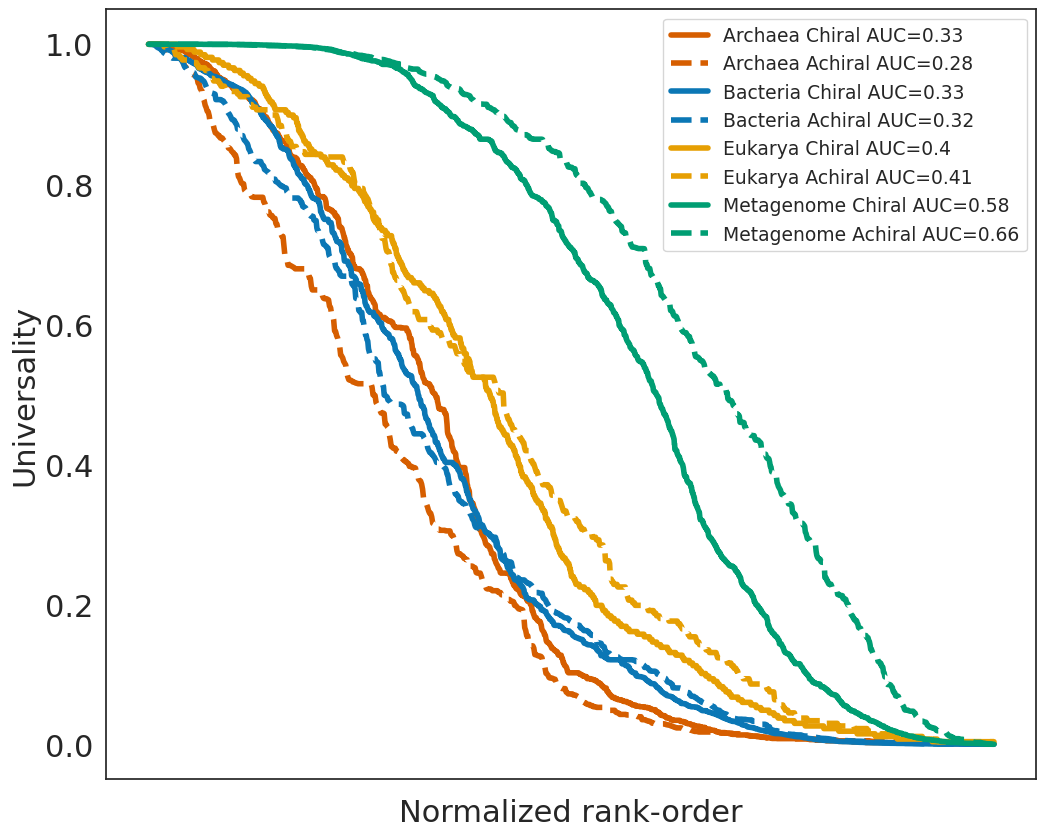

In [48]:
#All three domains together
fig, ax = plt.subplots(figsize=(12,10))
a_chiral = make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax)
a_achiral = make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax)

b_chiral = make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax)
b_achiral = make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax)

e_chiral = make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax)
e_achiral = make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax)

m_chiral = make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax)
m_achiral = make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax)

ax.set_ylabel("Universality", size=22)
ax.set_xlabel("Normalized rank-order", size=22)
ax.set_xticklabels("")
ax.tick_params(axis='both', which='major', labelsize=22)

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1


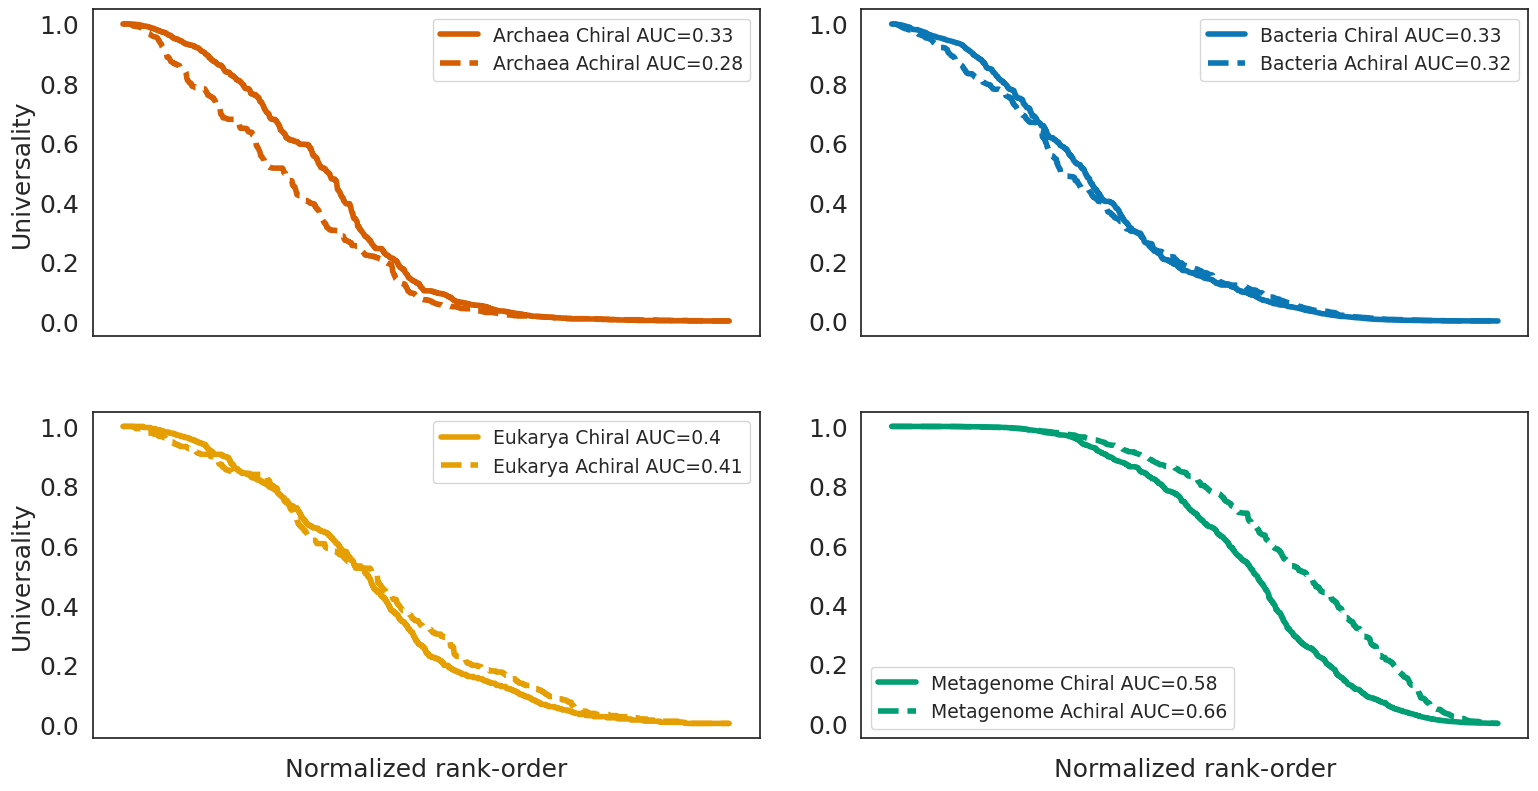

In [49]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(4,2)

ax1 = plt.subplot(gs[0,0])
make_AUC_dashes(a_chiral_universality, "Archaea Chiral", a_color, chiral_ls, ax1)
make_AUC_dashes(a_achiral_universality, "Archaea Achiral", a_color, achiral_ls, ax1)
ax1.set_xticklabels("")
ax1.tick_params(axis='both', which='major', labelsize=18)

ax2 = plt.subplot(gs[0,1])
make_AUC_dashes(b_chiral_universality, "Bacteria Chiral", b_color, chiral_ls, ax2)
make_AUC_dashes(b_achiral_universality, "Bacteria Achiral", b_color, achiral_ls, ax2)
ax2.set_xticklabels("")
ax2.tick_params(axis='both', which='major', labelsize=18)

ax3 = plt.subplot(gs[1,0])
make_AUC_dashes(e_chiral_universality, "Eukarya Chiral", e_color, chiral_ls, ax3)
make_AUC_dashes(e_achiral_universality, "Eukarya Achiral", e_color, achiral_ls, ax3)
ax3.set_xticklabels("")
ax3.tick_params(axis='both', which='major', labelsize=18)

ax4 = plt.subplot(gs[1,1])
make_AUC_dashes(m_chiral_universality, "Metagenome Chiral", mg_color, chiral_ls, ax4)
make_AUC_dashes(m_achiral_universality, "Metagenome Achiral", mg_color, achiral_ls, ax4)
ax4.set_xticklabels("")
ax4.tick_params(axis='both', which='major', labelsize=18)

ax1.set_ylabel("Universality", size=18)
ax3.set_ylabel("Universality", size=18)
ax3.set_xlabel("Normalized rank-order", size=18)
ax4.set_xlabel("Normalized rank-order", size=18)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1


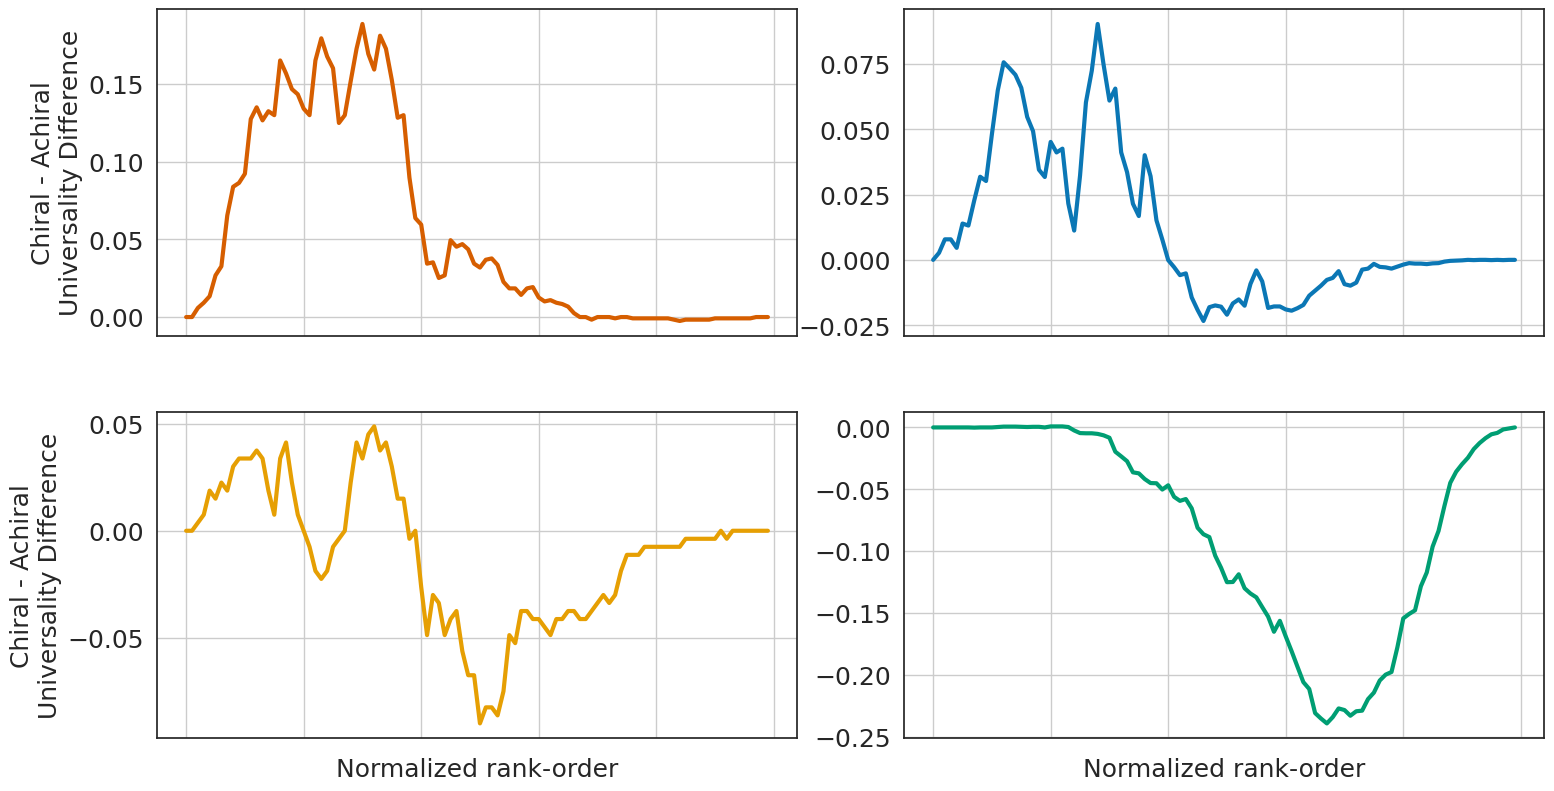

In [50]:
plt.figure(figsize=(16,16))
gs = gridspec.GridSpec(4,2)

ax1 = plt.subplot(gs[0,0])
get_chiral_difference(a_chiral, a_achiral, a_color, "Archaea", ax1)
ax1.set_xticklabels("")
ax1.tick_params(axis='both', which='major', labelsize=18)

ax2 = plt.subplot(gs[0,1])
get_chiral_difference(b_chiral, b_achiral, b_color, "Bacteria", ax2)
ax2.set_xticklabels("")
ax2.tick_params(axis='both', which='major', labelsize=18)

ax3 = plt.subplot(gs[1,0])
get_chiral_difference(e_chiral, e_achiral, e_color, "Eukarya", ax3)
ax3.set_xticklabels("")
ax3.tick_params(axis='both', which='major', labelsize=18)

ax4 = plt.subplot(gs[1,1])
get_chiral_difference(m_chiral, m_achiral, mg_color, "Metagenome", ax4)
ax4.set_xticklabels("")
ax4.tick_params(axis='both', which='major', labelsize=18)


ax1.set_ylabel("Chiral - Achiral\nUniversality Difference", size=18)
ax3.set_ylabel("Chiral - Achiral\nUniversality Difference", size=18)
ax3.set_xlabel("Normalized rank-order", size=18)
ax4.set_xlabel("Normalized rank-order", size=18)

ax1.grid()
ax2.grid()
ax3.grid()
ax4.grid()

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1


#### AUC scores for chiral modulating / conserving / achiral conserving domain-specific reactions

In [51]:
def get_AUC(yvals):
  xvals = np.linspace(0, 1, num=len(yvals))
  #Calculate AUC using composite travezoidal rule
  area = np.trapezoid(yvals, dx=xvals[1])
  return round(area, 3)

def plot_classes(universality, ax, c, title):
  modulating_universality = [u for r, u in universality.items() if r in modulating_rxns]
  chiral_conserve_universality = [u for r, u in universality.items() if r in chiral_conserving_rxns]
  achiral_conserve_universality = [u for r, u in universality.items() if r in achiral_conserving_rxns]

  ax.plot(modulating_universality, linestyle="solid", linewidth=3, color=c, label=f"Chiral Modulating\nAUC={get_AUC(modulating_universality)}")
  ax.plot(chiral_conserve_universality, linestyle="dashed", linewidth=3, color=c, label=f"Chiral Conserving\nAUC={get_AUC(chiral_conserve_universality)}")
  ax.plot(achiral_conserve_universality, linestyle="dotted", linewidth=3, color=c, label=f"Achiral Conserving\nAUC={get_AUC(achiral_conserve_universality)}")

  ax.legend(facecolor="white", prop={"size": 8})
  ax.set_title(title, color=c, size=20)

### Modulating - from Kamesh
modulate_df = pd.read_csv("../Data/kegg_reactions_with_mol_weights_comprehensive_v8.csv")

modulating = []
achiral_conserve = []
chiral_conserve = []

modulating_rxns = []
achiral_conserving_rxns = []
chiral_conserving_rxns = []

for i in range(0, max(modulate_df["Network_step"])):
    sub_df = modulate_df[modulate_df["Network_step"] == i]

    chiral_modulating_df = sub_df[sub_df["Chiral_modulating"] == 1]
    modulating.append(len(chiral_modulating_df))
    if not chiral_modulating_df.empty:
        modulating_rxns.extend(list(chiral_modulating_df["_key"]))
    
    achiral_conserving_df = sub_df[sub_df["Achiral_conserving"] == 1]
    achiral_conserve.append(len(achiral_conserving_df))
    if not achiral_conserving_df.empty:
        achiral_conserving_rxns.extend(list(achiral_conserving_df["_key"]))

    chiral_conserving_df = sub_df[sub_df["Chiral_conserving"] == 1]
    chiral_conserve.append(len(chiral_conserving_df))
    if not chiral_conserving_df.empty:
        chiral_conserving_rxns.extend(list(chiral_conserving_df["_key"]))

### Read in occurence data & create universality percentages
num_bacteria = 11759
num_archaea = 1282
num_eukarya = 243
num_metagenomes = 18725

with open("../Data/Archaea_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_rxn_occurances = dict(reader)

with open("../Data/Bacteria_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_rxn_occurances = dict(reader)

with open("../Data/Eukaryota_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_rxn_occurances = dict(reader)

with open("../Data/Metagenome_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_rxn_occurances = dict(reader)

#Translate occurances into % universality
a_rxn_universality = {}
b_rxn_universality = {}
e_rxn_universality = {}
m_rxn_universality = {}

#Num archaea: 1194
for item in a_rxn_occurances.items():
  a_rxn_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_rxn_occurances.items():
  b_rxn_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_rxn_occurances.items():
  e_rxn_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_rxn_occurances.items():
  m_rxn_universality[item[0]] = float(item[1]) / num_metagenomes

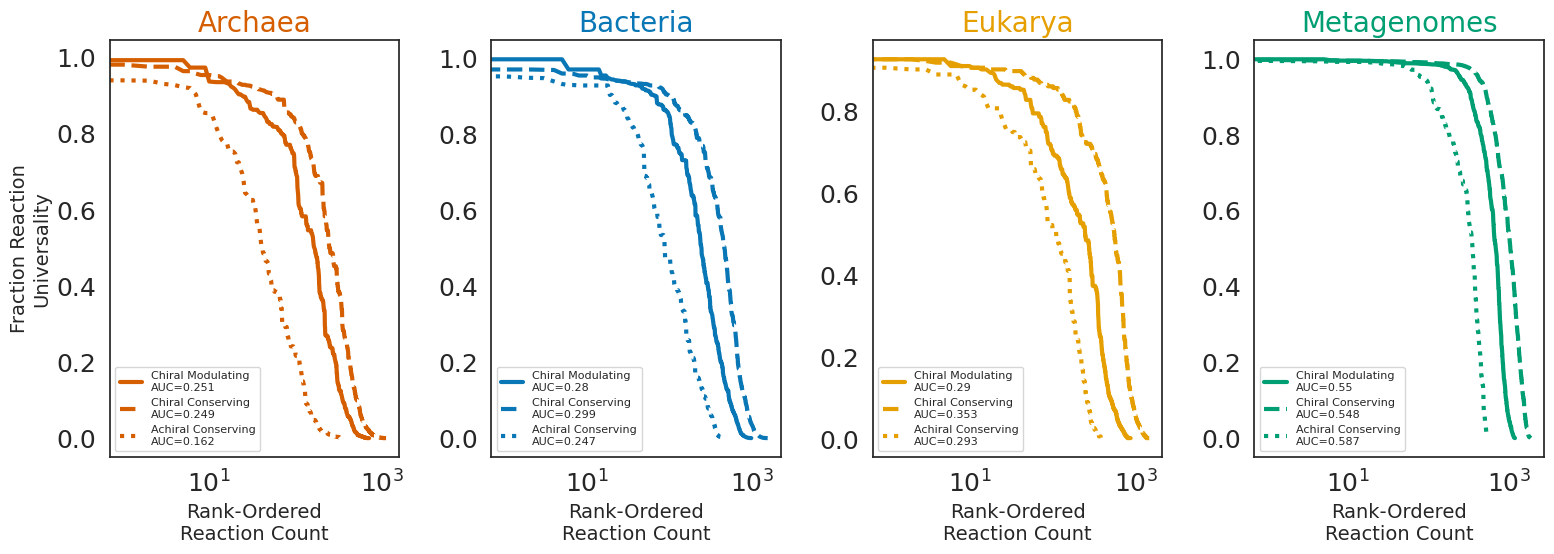

In [52]:
### Goal - 4 plots (1 per domain) with AUC scores in legend
from matplotlib.gridspec import GridSpec

colors = {"archaea": "#D55E00", 
         "bacteria": "#0977B5",
         "eukarya": "#E69F00",
         "metagenome": "#009E73",
         "pantaxa": "#EA9999",
          "chiral": "#34CCFF",
          "achiral": "#FFC012",
          "mixed": "#abdbfc",
          "luca": "grey"}

fig = plt.figure(figsize=(16,6))
gs = GridSpec(1,4)

ax_archaea = fig.add_subplot(gs[:, 0])
ax_bacteria = fig.add_subplot(gs[:,1])
ax_eukarya= fig.add_subplot(gs[:, 2])
ax_mg = fig.add_subplot(gs[:, 3])

plot_classes(a_rxn_universality, ax_archaea, colors["archaea"], "Archaea")
plot_classes(b_rxn_universality, ax_bacteria, colors["bacteria"], "Bacteria")
plot_classes(e_rxn_universality, ax_eukarya, colors["eukarya"], "Eukarya")
plot_classes(m_rxn_universality, ax_mg, colors["metagenome"], "Metagenomes")

ax_archaea.set_xscale("log")
ax_bacteria.set_xscale("log")
ax_eukarya.set_xscale("log")
ax_mg.set_xscale("log")

ax_archaea.tick_params(axis='both', which='major', labelsize=18)
ax_bacteria.tick_params(axis='both', which='major', labelsize=18)
ax_eukarya.tick_params(axis='both', which='major', labelsize=18)
ax_mg.tick_params(axis='both', which='major', labelsize=18)

ax_archaea.set_ylabel("Fraction Reaction\nUniversality", fontsize=14)
ax_archaea.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_bacteria.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_eukarya.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_mg.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)

plt.tight_layout()

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

# Reaxys Sampling


In [53]:
#Matplotlib defaults
chnops_color = "#477C7D"
kegg_color = "#AA0E35"

chnops = pickle.load(file=open("../Data/chiral_chnops_sampling_FULL.p", "rb"))
kegg = pickle.load(file=open("../Data/chiral_kegg_sampling_FULL.p", "rb"))
mws = np.arange(100,7100,100) #Molecular Weights (x-axis)

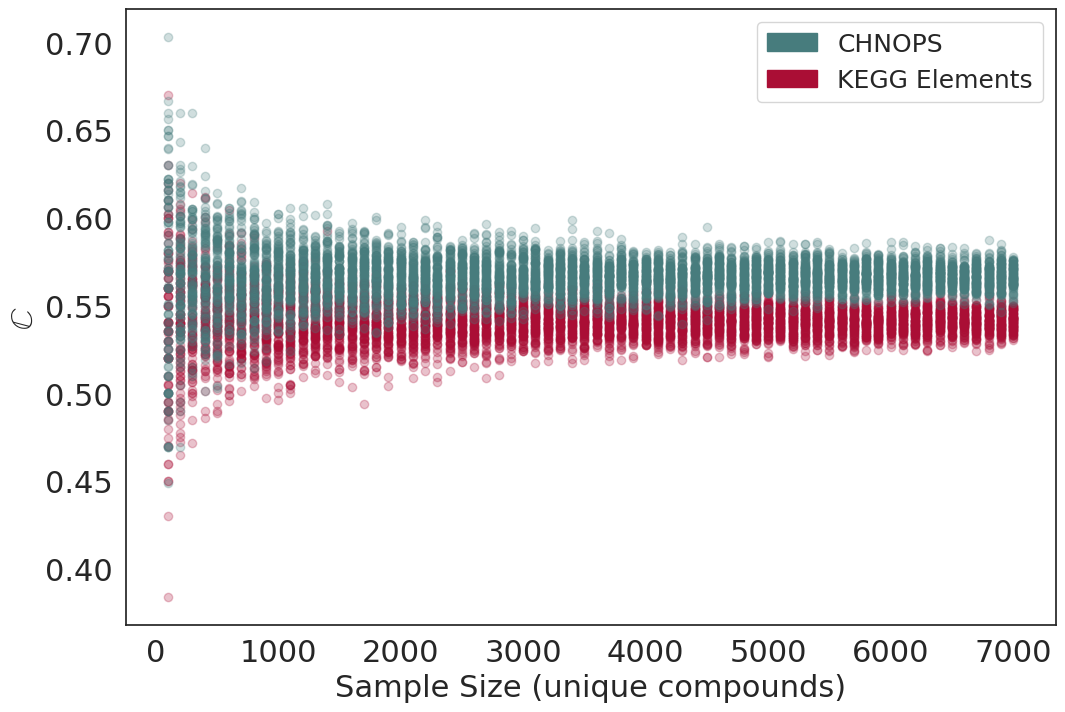

In [54]:
fig, ax = plt.subplots(figsize=(12,8))

#Scatter plot first
for i in range(len(chnops)):
    ax.scatter([mws[i]] * len(kegg[i]), kegg[i], color=kegg_color, alpha=0.25)
    ax.scatter([mws[i]] * len(chnops[i]), chnops[i], color=chnops_color, alpha=0.25)

ax.set_ylabel("$\mathbb{C}$", size=22)
ax.set_xlabel("Sample Size (unique compounds)", size=22)

ax.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

ax.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1


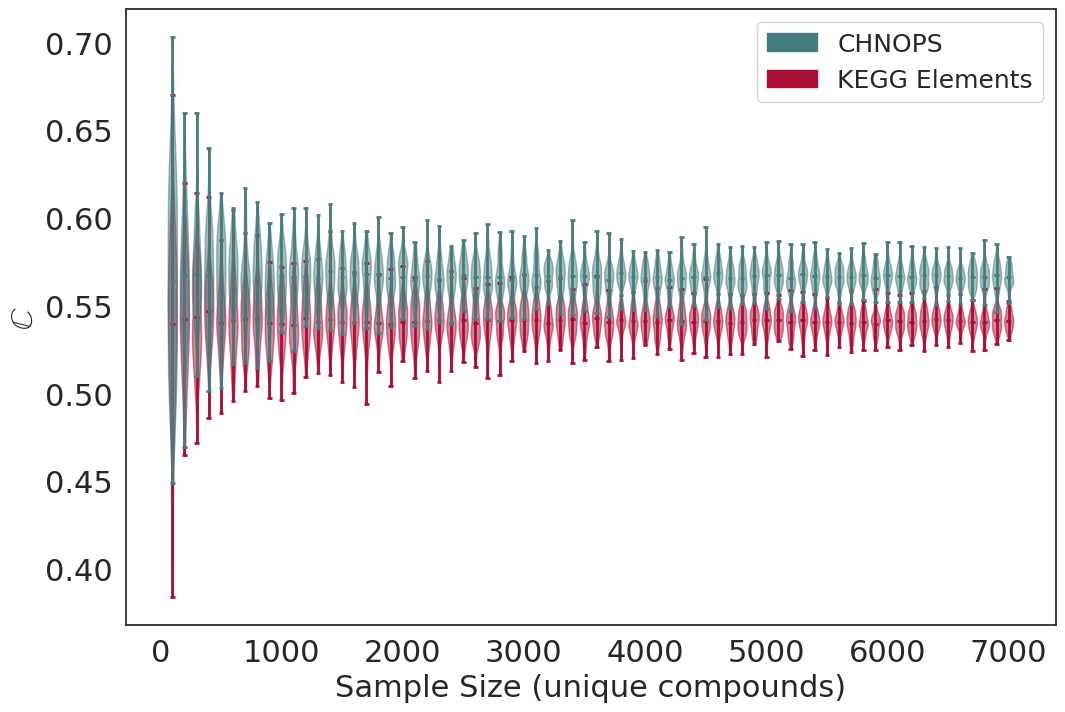

In [55]:
fig, ax = plt.subplots(1,1,figsize=(12,8))

#Violin plots second
kegg_violins = ax.violinplot(kegg, positions=mws, widths=75, showmeans=True)
chnops_violins = ax.violinplot(chnops, positions=mws, widths=75, showmeans=True)

# Color all CHNOPS violins
for partname in ('cbars','cmins','cmaxes','cmeans'):
    vp = chnops_violins[partname]
    vp.set_edgecolor(chnops_color)
    vp.set_linewidth(2)

for pc in chnops_violins['bodies']:
    pc.set_facecolor(chnops_color)
    pc.set_edgecolor(chnops_color)
    pc.set_alpha(0.5)

#Now do all KEGG violins
for partname in ('cbars','cmins','cmaxes','cmeans'):
    vp = kegg_violins[partname]
    vp.set_edgecolor(kegg_color)
    vp.set_linewidth(2)

for pc in kegg_violins['bodies']:
    pc.set_facecolor(kegg_color)
    pc.set_edgecolor(kegg_color)
    pc.set_alpha(0.5)

ax.set_ylabel("$\mathbb{C}$", size=22)
ax.set_xlabel("Sample Size (unique compounds)", size=22)

ax.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

plt.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18})

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1

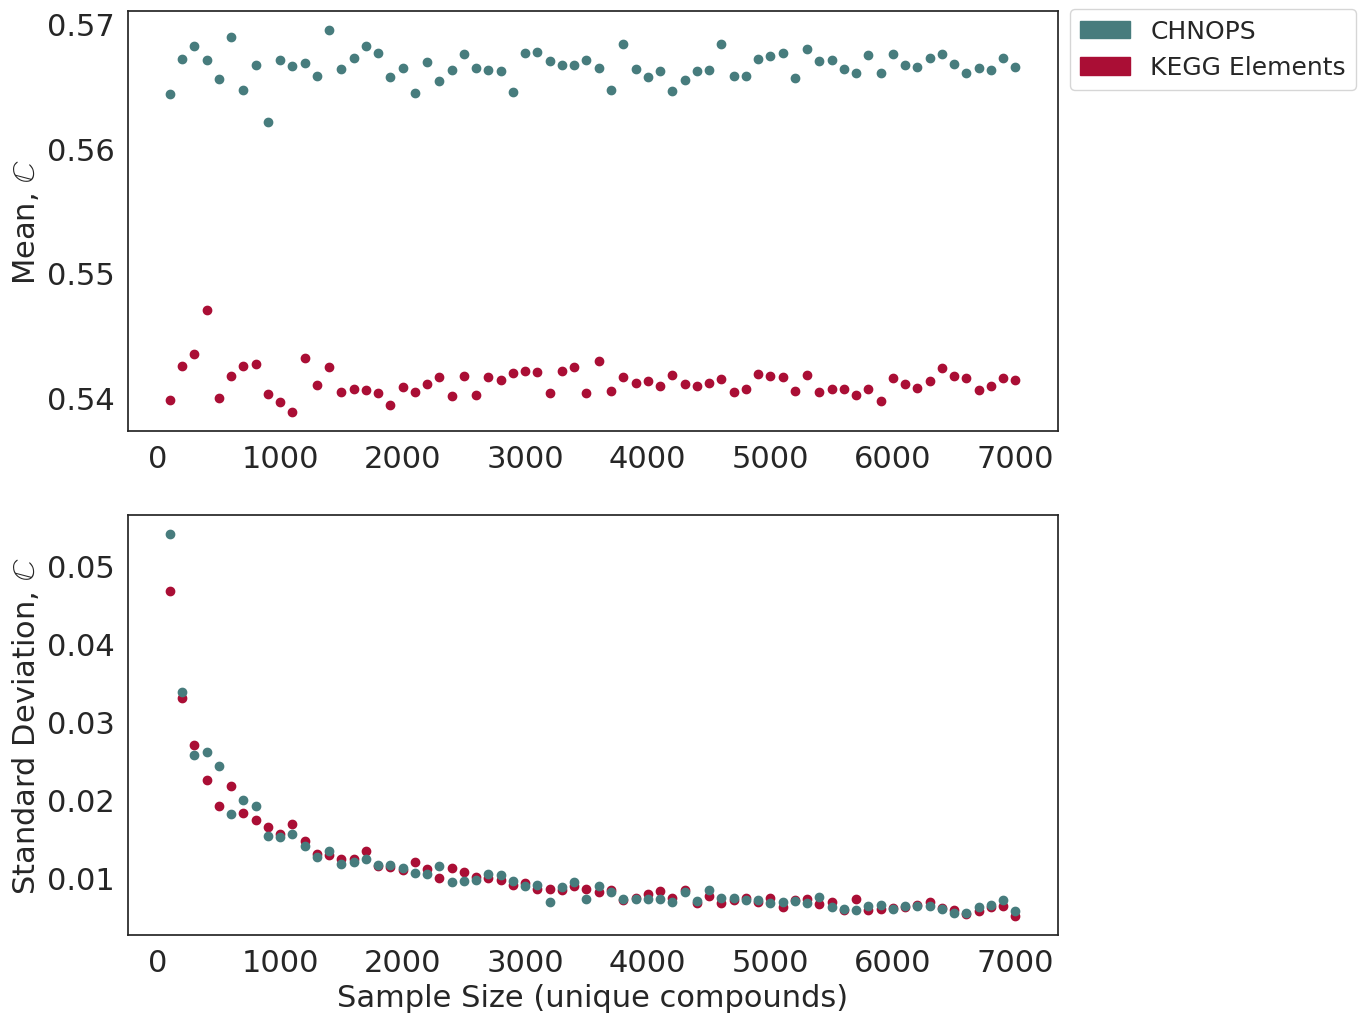

In [56]:
## Mean & StdDev of all samples
plt.figure(figsize=(12,12))
gs = gridspec.GridSpec(2,1)

#Means
ax1 = plt.subplot(gs[0,0])
ax1.scatter(mws, [np.mean(s) for s in kegg], color=kegg_color)
ax1.scatter(mws, [np.mean(s) for s in chnops], color=chnops_color)
ax1.set_ylabel("Mean, $\mathbb{C}$", size=22)
ax1.tick_params(axis='both', which='major', labelsize=22)


#Stdevs
ax2 = plt.subplot(gs[1,0])
ax2.scatter(mws, [np.std(s) for s in kegg], color=kegg_color)
ax2.scatter(mws, [np.std(s) for s in chnops], color=chnops_color)
ax2.set_ylabel("Standard Deviation, $\mathbb{C}$", size=22)
ax2.set_xlabel("Sample Size (unique compounds)", size=22)
ax2.tick_params(axis='both', which='major', labelsize=22)

#Legend
chnops_patch = mpatches.Patch(color=chnops_color, label='CHNOPS')
kegg_patch = mpatches.Patch(color=kegg_color, label='KEGG Elements')

ax1.legend(handles=[chnops_patch, kegg_patch], facecolor="white", prop={"size": 18}, bbox_to_anchor=(1,1.035))

plt.savefig(f"{fig_path}{fig_count}.svg", format="svg")
fig_count+=1